# CNN Project: From Scratch to State of the Art on CIFAR-10

**Estimated time:** 8–12 hours  |  **Total:** 100 points + 10 bonus  |  **Hardware:** Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU)

<font color='red'> **Make a copy of this notebook in your own Google Drive before you start (File → Save a copy in Drive), or your work will be lost.** </font>

---

## Project Overview

In this project you will build an image classifier for the **CIFAR-10** dataset: 60,000 small (32×32) colour photographs, each belonging to one of ten classes:

| 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| airplane | automobile | bird | cat | deer | dog | frog | horse | ship | truck |

Unlike a step-by-step tutorial, this project asks you to **predict before you run, justify every design decision, and analyse why your model fails**. You will move through the same journey a practitioner follows on a real problem:

| Problem | Topic | What you will learn | Points |
|---|---|---|---|
| 0 | Data understanding & preprocessing | Splits, class balance, memory-efficient pipelines | 8 |
| 1 | Baseline CNN | Building from a spec, shapes and parameters by hand | 17 |
| 2 | Architecture experiments | Global pooling, Batch Normalization, deeper blocks, Dropout | 20 |
| 3 | Augmentation & training control | Label-preserving augmentation, callbacks, learning-rate schedules | 15 |
| 4 | Transfer learning & fine-tuning | MobileNetV2, preprocessing traps, two-phase fine-tuning | 20 |
| 5 | Error analysis & interpretability | Confusion analysis, failure galleries, **Grad-CAM from scratch** | 12 |
| 6 | Data-efficiency study | When does transfer learning matter most? | 8 |
| 7 | **Bonus challenge** | Beat an accuracy target under a parameter budget | +10 |

## How this notebook works

You will see four kinds of task cells:

* `### YOUR CODE HERE ###` — write code.
* 🔮 **Predict first** — write down a number *before* you run the code. A checker tells you whether you were right. Your prediction is graded on your *reasoning*, not only on being correct, so show your work.
* ✍️ <font color='red'>**Your Answer**</font> — written explanation. Aim for 3–6 sentences that cite *your own* numbers and plots.
* ✅ **Self-check** cells — run them; they catch common mistakes early. A passing self-check does not guarantee full marks.

## Rules of the game

1. **The test set is for reporting, not for decisions.** Choose architectures, epochs and hyperparameters using the *validation* set only. Using test accuracy to make choices is a form of data leakage, and in Problem 7 it is disqualifying.
2. **Keep the seed fixed** so your results are reproducible.
3. **Cite your evidence.** "Model B is better" is not an answer; "Model B reaches 78.4% validation accuracy versus 71.2% for Model A, and its train–validation gap shrinks from 19 to 6 points" is.
4. You may use any documentation, but every line of code you submit must be code you can explain.

# Setup

Run the cells below. The first cell confirms that you are on a GPU; training without one will be 10–30× slower.

In [62]:
import os, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from sklearn import metrics
from sklearn.model_selection import train_test_split
from IPython.display import display

# Fix all random seeds (Python, NumPy, TensorFlow) so results are reproducible
SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO GPU - switch runtime to GPU before continuing!")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [63]:
# Global training settings. You may lower EPOCHS while debugging,
# but your final submitted runs must use the values below unless a problem says otherwise.
BATCH_SIZE = 64
EPOCHS = 20

### Helper utilities (provided)

These helpers are given to you so that every experiment is evaluated the same way. **Read them before using them** — several questions later in the project assume you understand what they compute.

* `plot_history(history)` plots accuracy **and** loss for training and validation.
* `record(name, model, history)` evaluates a model and saves its key numbers to the `RESULTS` table.
* `show_results()` displays every experiment you have recorded, side by side.
* `check(label, value, expected)` is a small self-check helper.

In [64]:
RESULTS = {}

def plot_history(history, title=""):
    # Plot training/validation accuracy and loss side by side.
    h = history.history
    epochs = range(1, len(h["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, h["accuracy"], "o-", label="train")
    axes[0].plot(epochs, h["val_accuracy"], "s-", label="validation")
    axes[0].set(title=f"{title} accuracy", xlabel="epoch", ylabel="accuracy")
    axes[1].plot(epochs, h["loss"], "o-", label="train")
    axes[1].plot(epochs, h["val_loss"], "s-", label="validation")
    axes[1].set(title=f"{title} loss", xlabel="epoch", ylabel="loss")
    for ax in axes:
        ax.legend(); ax.grid(alpha=0.3)
    plt.show()

def record(name, model, history):
    # Evaluate on validation and test sets and store the summary in RESULTS.
    h = history.history
    best_epoch = int(np.argmax(h["val_accuracy"]))
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    RESULTS[name] = {
        "total_params": model.count_params(),
        "trainable_params": trainable,
        "epochs_run": len(h["accuracy"]),
        "best_val_acc": round(h["val_accuracy"][best_epoch], 4),
        "train_acc@best": round(h["accuracy"][best_epoch], 4),
        "gap@best": round(h["accuracy"][best_epoch] - h["val_accuracy"][best_epoch], 4),
        "test_acc": round(test_acc, 4),
    }
    print(f"[{name}] best val acc = {RESULTS[name]['best_val_acc']:.4f} | test acc = {test_acc:.4f}")

def show_results():
    display(pd.DataFrame(RESULTS).T)

def check(label, value, expected):
    if value is None:
        print(f"⚠️  {label}: you have not filled this in yet.")
    elif value == expected:
        print(f"✅ {label}: correct ({value:,})")
    else:
        print(f"❌ {label}: you predicted {value:,} but the model has {expected:,}. Find the error in your reasoning and explain it in your answer.")

# Problem 0: Data Understanding & Preprocessing [8 points]

Keras ships CIFAR-10 directly, so no download link is needed.

In [65]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.squeeze()   # shape (50000, 1) -> (50000,)
y_test = y_test.squeeze()

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("train:", x_train_full.shape, x_train_full.dtype, "| test:", x_test.shape)
print("pixel range:", x_train_full.min(), "to", x_train_full.max())

train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
pixel range: 0 to 255


## Part (a): Explore the data [2 points]

1. Plot a 4×8 grid of random training images with their class names as titles.
2. Plot a bar chart of how many images belong to each class in the training set.

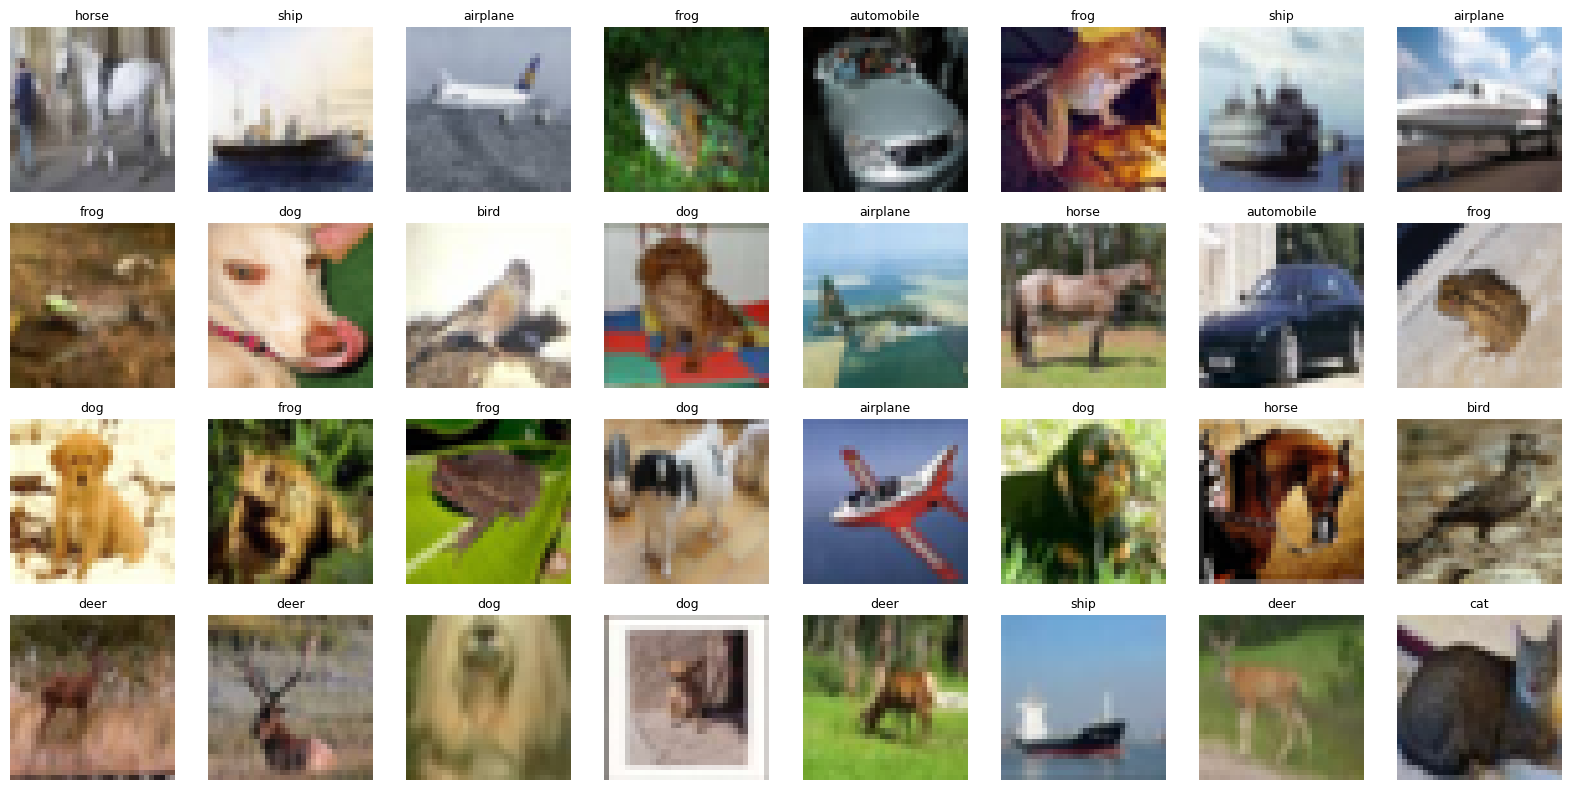

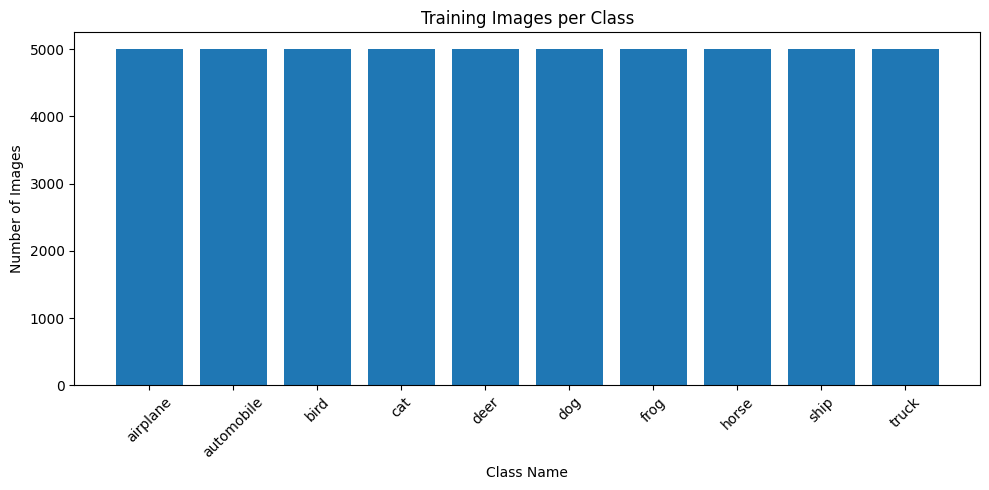

In [66]:

import numpy as np
import matplotlib.pyplot as plt

# Select 32 random training images
indices = np.random.choice(len(x_train_full), 32, replace=False)

# Show images in a 4 x 8 grid
plt.figure(figsize=(16, 8))

for i, idx in enumerate(indices):
    plt.subplot(4, 8, i + 1)
    plt.imshow(x_train_full[idx])
    plt.title(CLASS_NAMES[int(y_train_full[idx])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Count images in each class
class_counts = np.bincount(y_train_full, minlength=10)

# Show the class counts in a bar chart
plt.figure(figsize=(10, 5))
plt.bar(CLASS_NAMES, class_counts)
plt.xlabel("Class Name")
plt.ylabel("Number of Images")
plt.title("Training Images per Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


✍️ Is the dataset balanced? Why does the answer matter for how you interpret *accuracy* as a metric? Give one example of a dataset where accuracy would be a misleading metric.

<font color='red'>**Your Answer.**</font>

__# The dataset is balanced if both classes have a similar number of images.

Accuracy tells us the percentage of correct predictions, but it can be misleading
when one class has many more examples than the other.
For example, if 95% of patients do not have a disease, a model that always
predicts "no disease" gets 95% accuracy but fails to identify sick patients._

## Part (b): A proper validation split [3 points]

In many tutorials, `model.fit(..., validation_split=0.2)` is used. That option simply takes the **last** 20% of the array as validation data, without shuffling.

Instead, create an explicit **stratified** split with `train_test_split`: hold out **5,000** images for validation, use `stratify=y_train_full` and `random_state=SEED`. Store the results in `x_train, x_val, y_train, y_val`.

In [67]:
### YOUR CODE HERE ###
x_train, x_val, y_train, y_val = None, None, None, None

from sklearn.model_selection import train_test_split

# Split 5000 images for validation
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=5000,
    stratify=y_train_full,
    random_state=SEED
)

# Check the sizes
print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)


Training images: (45000, 32, 32, 3)
Validation images: (5000, 32, 32, 3)
Training labels: (45000,)
Validation labels: (5000,)


In [68]:
# ✅ Self-check
assert x_train.shape == (45000, 32, 32, 3), f"x_train has shape {x_train.shape}"
assert x_val.shape == (5000, 32, 32, 3), f"x_val has shape {x_val.shape}"
assert np.all(np.bincount(y_val) == 500), "Validation set is not stratified (each class should have exactly 500 images)"
print("✅ Split looks correct")

✅ Split looks correct


✍️ Answer both:

1. Describe a concrete situation where `validation_split=0.2` (last 20%, unshuffled) would give a badly misleading validation score.
2. Why do we need a validation set at all when we already have a test set?

<font color='red'>**Your Answer.**</font>

_# 1. If the dataset is sorted by class, for example, the first 80% contains

cats and the last 20% contains dogs, the validation score can be misleading
because the training and validation data are different.

2. We use the validation set to tune the model and choose the best settings
during training. The test set is used at the end to check how well the final
model performs on unseen data. Using the test set repeatedly can lead to biased results..__

## Part (c): Labels and memory [3 points]

Notice two choices we make in this project that differ from many tutorials:

* **Integer labels, not one-hot.** `y_train` contains integers 0–9, and we will use the `sparse_categorical_crossentropy` loss.
* **Images stay as `uint8`.** We will **not** divide by 255 in NumPy. Instead, every model begins with a `Rescaling` layer that converts pixels to floats inside the network.

Compute (in code) how many megabytes `x_train` occupies as `uint8`, and how many it would occupy as `float32`.

In [69]:
### YOUR CODE HERE ###

# Calculate memory used by x_train

uint8_mb = x_train.nbytes / (1024 ** 2)
float32_mb = x_train.size * 4 / (1024 ** 2)

print("Memory as uint8:", uint8_mb, "MB")
print("Memory as float32:", float32_mb, "MB")


Memory as uint8: 131.8359375 MB
Memory as float32: 527.34375 MB


✍️ Answer both:

1. Mathematically, is `sparse_categorical_crossentropy` with integer labels different from `categorical_crossentropy` with one-hot labels? When would you prefer one over the other?
2. Give two advantages of doing rescaling *inside* the model (as a layer) rather than in NumPy beforehand. Hint: think about memory and about what happens when the model is deployed.

<font color='red'>**Your Answer.**</font>

_### 1. Sparse Categorical Crossentropy vs Categorical Crossentropy

Mathematically, both loss functions calculate the same loss. The difference is in how labels are provided.

- **Sparse categorical crossentropy:** Uses integer labels, such as `0`, `1`, or `2`.
- **Categorical crossentropy:** Uses one-hot encoded labels, such as `[1,0,0]`, `[0,1,0]`, or `[0,0,1]`.

I prefer sparse categorical crossentropy when labels are integers because it uses less memory and does not require one-hot encoding. Categorical crossentropy is useful when labels are already one-hot encoded.

### 2. Advantages of Rescaling Inside the Model

**Advantage 1 — Saves memory:** We do not need to create a separate normalized copy of the entire dataset in NumPy. Rescaling can happen as the model processes batches of images.

**Advantage 2 — Easier deployment:** Rescaling becomes part of the model, so the same preprocessing is applied during training and prediction. This reduces the risk of forgetting to normalize input images when deploying the model.
_

# Problem 1: Baseline CNN [17 points]

## Part (a): Build the model from a specification [5 points]

Build `baseline` using the Keras **Functional API** exactly as specified below. All convolutions use a 3×3 kernel, `padding="same"` and ReLU activation. All pooling layers are 2×2 max pooling.

| # | Layer | Configuration |
|---|---|---|
| 1 | Input | shape (32, 32, 3) |
| 2 | Rescaling | scale 1/255 |
| 3 | Conv2D | 32 filters |
| 4 | MaxPooling2D | 2×2 |
| 5 | Conv2D | 64 filters |
| 6 | MaxPooling2D | 2×2 |
| 7 | Conv2D | 128 filters |
| 8 | MaxPooling2D | 2×2 |
| 9 | Flatten | |
| 10 | Dense | 128 units, ReLU |
| 11 | Dense (output) | 10 units, *choose the correct activation* |

The finished model has **356,810** parameters.

In [70]:

from tensorflow import keras
from tensorflow.keras import layers

# Input layer
inputs = keras.Input(shape=(32, 32, 3))

# Rescale pixels
x = layers.Rescaling(1./255)(inputs)

# Convolution and pooling layers
x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Dense layers
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)

# Output layer
outputs = layers.Dense(10, activation="softmax")(x)

# Create model
baseline = keras.Model(inputs, outputs, name="baseline")

baseline.summary()
print("Total parameters:", baseline.count_params())


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_8 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 356810


In [71]:
# ✅ Self-check
assert baseline.count_params() == 356_810, f"Expected 356,810 parameters, found {baseline.count_params():,}"
assert baseline.output_shape == (None, 10)
print("✅ Architecture matches the specification")

✅ Architecture matches the specification


## Part (b): Shapes and parameters by hand [6 points]

Without looking at `baseline.summary()`, fill in the table below **by hand**. For each parameter count, show the formula (for example, `896 = 3·3·3·32 + 32`).

| Layer | Output shape | # Parameters | Formula |
|---|---|---|---|
| Conv2D (32) | | | |
| MaxPooling2D | | | |
| Conv2D (64) | | | |
| MaxPooling2D | | | |
| Conv2D (128) | | | |
| MaxPooling2D | | | |
| Flatten | | | |
| Dense (128) | | | |
| Dense (10) | | | |

Then answer:

1. Which single layer holds the most parameters, and what fraction of the total is it? What does this suggest about where the model might be overfitting?
2. If we replaced the whole convolutional part with a plain MLP — `Flatten` the raw 32×32×3 image and feed it directly into a `Dense(128)` layer — how many parameters would that one Dense layer have? Compare it with the parameter count of all three Conv2D layers combined, and explain in terms of **weight sharing** and **local connectivity** why CNNs suit images better.
3. How would the output shape of the first Conv2D change if we used `padding="valid"` instead of `"same"`?

<font color='red'>**Your Answer.**</font>

1. The Dense layer usually has the most parameters because it connects
every input to every neuron. A layer with many parameters may overfit
by memorizing the training images instead of learning general patterns.
2. A 32x32x3 image has 3072 values. A Dense(128) layer has
3072 * 128 + 128 = 393344 parameters.
CNNs use weight sharing, meaning the same filter is used across the image.
They also use local connectivity, meaning each filter looks at a small
region. This reduces parameters and helps CNNs learn image features.
The exact parameter count of the three Conv2D layers depends on their
filter counts and kernel sizes.
3. With padding="valid", no padding is added, so the output becomes
smaller. For a 3x3 kernel, stride 1, and a 32x32 input, the output
changes from 32x32 (same padding) to 30x30 (valid padding)._

## Part (c): Train and evaluate [6 points]

Compile `baseline` with the `adam` optimizer, `sparse_categorical_crossentropy` loss and the `accuracy` metric. Train it on `(x_train, y_train)` for `EPOCHS` epochs with `BATCH_SIZE`, passing `validation_data=(x_val, y_val)`. Store the result in `baseline_history`.

In [72]:

baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_ = baseline.fit(
    x=x_train,
    y=y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val)
)


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4654 - loss: 1.4710 - val_accuracy: 0.5832 - val_loss: 1.1588
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6242 - loss: 1.0621 - val_accuracy: 0.6508 - val_loss: 0.9927
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6895 - loss: 0.8878 - val_accuracy: 0.6878 - val_loss: 0.9023
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7344 - loss: 0.7688 - val_accuracy: 0.6936 - val_loss: 0.9168
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7677 - loss: 0.6745 - val_accuracy: 0.7058 - val_loss: 0.8948
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7934 - loss: 0.5977 - val_accuracy: 0.7166 - val_loss: 0.8918
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8163 - loss: 0.5287 - val_accuracy: 0.7168 - val_loss: 0.8957
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8342 - loss: 0.4767 - val_accuracy: 0.

In [73]:
%whos

Variable                Type             Data/Info
--------------------------------------------------
BATCH_SIZE              int              64
CLASS_NAMES             list             n=10
EPOCHS                  int              20
RESULTS                 dict             n=0
SEED                    int              42
aug_model               Functional       <Functional name=aug_model, built=True>
augment                 Sequential       <Sequential name=augment, built=True>
augmented_images        EagerTensor      tf.Tensor(\n[[[[  8.61003<...>2, 32, 3), dtype=float32)
base                    Functional       <Functional name=mobilenetv2_1.00_96, built=True>
base_full               Functional       <Functional name=mobilenetv2_1.00_96, built=True>
base_index              int              4
base_model              Functional       <Functional name=mobilenetv2_1.00_96, built=True>
baseline                Functional       <Functional name=baseline, built=True>
baseline_             

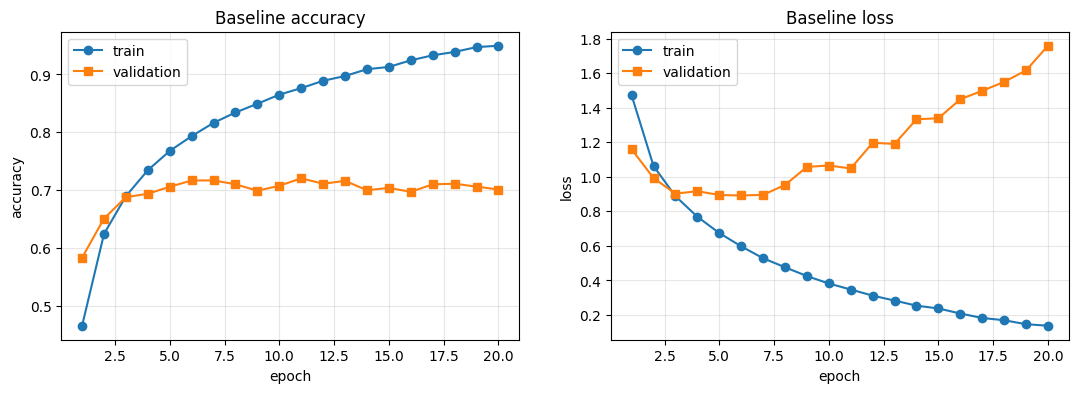

[baseline] best val acc = 0.7204 | test acc = 0.7065


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7204,0.8763,0.1559,0.7065


In [74]:
plot_history(baseline_, "Baseline")
record("baseline", baseline, baseline_)
show_results()

✍️ Answer all:

1. How many batches (steps) are there per epoch? Show the calculation. Why is it not a whole number before rounding, and what does Keras do with the leftover images?
2. In your own words, explain the relationship between a **batch**, an **epoch** and one **gradient update**.
3. Using **both** plots (accuracy *and* loss), identify the epoch at which the model starts to overfit. Explain why the validation *loss* often reveals overfitting earlier than validation *accuracy* does.

<font color='red'>**Your Answer.**</font>

_
1. Steps per epoch are calculated by dividing the number of training
images by the batch size and rounding up.
Steps per epoch = ceil(number of training images / batch size)
It may not be a whole number because the images may not divide evenly
into batches. Keras uses the remaining images as a smaller final batch.
2. A batch is a small group of images processed together.
An epoch means the model has processed the entire training dataset once.
One gradient update usually happens after each batch, when the model
updates its weights to reduce the loss.
3. Overfitting starts when training accuracy keeps increasing and
training loss keeps decreasing, but validation accuracy stops improving
or decreases and validation loss starts increasing.
The exact epoch should be identified from both plots.
Validation loss can reveal overfitting earlier because it measures
how wrong the predictions are and how confident they are.
Accuracy only counts correct and incorrect predictions, so it may
remain stable even when the model becomes overconfident on wrong answers.
._

# Problem 2: Architecture Experiments [20 points]

You will now change the architecture **one idea at a time**, so that each change can be attributed to its cause. This is the discipline of a *controlled experiment*.

Every model in this problem must be compiled and trained exactly like `baseline` (same optimizer, loss, epochs, batch size and validation data). Write a helper `compile_and_fit(model)` once and reuse it.

In [75]:

def compile_and_fit(model, epochs=EPOCHS, callbacks=None, optimizer="adam"):
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    return history


## Part (a): Global Average Pooling [5 points]

Build `gap_model`: identical to `baseline`, except replace `Flatten` with `GlobalAveragePooling2D`.

🔮 **Predict first.** Before building it, compute the total number of parameters of `gap_model` by hand and write it in `pred_gap_params`.

In [76]:

from tensorflow import keras
from tensorflow.keras import layers

# Input layer
inputs = keras.Input(shape=(32, 32, 3))

# Rescale images
x = layers.Rescaling(1./255)(inputs)

# Convolution and pooling layers
x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Global Average Pooling instead of Flatten
x = layers.GlobalAveragePooling2D()(x)

# Dense layers
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)

# Create GAP model
gap_model = keras.Model(inputs, outputs, name="gap_model")

gap_model.summary()
print("Total parameters:", gap_model.count_params())


Model: "gap_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_20 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_9 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 111050


In [77]:
%whos

Variable                Type             Data/Info
--------------------------------------------------
BATCH_SIZE              int              64
CLASS_NAMES             list             n=10
EPOCHS                  int              20
RESULTS                 dict             n=1
SEED                    int              42
aug_model               Functional       <Functional name=aug_model, built=True>
augment                 Sequential       <Sequential name=augment, built=True>
augmented_images        EagerTensor      tf.Tensor(\n[[[[  8.61003<...>2, 32, 3), dtype=float32)
base                    Functional       <Functional name=mobilenetv2_1.00_96, built=True>
base_full               Functional       <Functional name=mobilenetv2_1.00_96, built=True>
base_index              int              4
base_model              Functional       <Functional name=mobilenetv2_1.00_96, built=True>
baseline                Functional       <Functional name=baseline, built=True>
baseline_             

In [78]:
gap_history = compile_and_fit(gap_model, epochs=EPOCHS)

print("Gap history:", gap_history)
print("Gap model parameters:", gap_model.count_params())
print("Training data shape:", x_train.shape)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.3366 - loss: 1.7713 - val_accuracy: 0.4188 - val_loss: 1.5775
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4650 - loss: 1.4612 - val_accuracy: 0.5024 - val_loss: 1.3597
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5322 - loss: 1.2908 - val_accuracy: 0.5610 - val_loss: 1.2073
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5748 - loss: 1.1754 - val_accuracy: 0.5892 - val_loss: 1.1355
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6091 - loss: 1.0894 - val_accuracy: 0.6066 - val_loss: 1.0844
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6365 - loss: 1.0212 - val_accuracy: 0.6286 - val_loss: 1.0304
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6564 - loss: 0.9656 - val_accuracy: 0.6312 - val_loss: 1.0252
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6764 - loss: 0.9151 - val_accuracy: 0.

In [79]:


gap_history = compile_and_fit(gap_model)

print(gap_history)


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8240 - loss: 0.5098 - val_accuracy: 0.7222 - val_loss: 0.8713
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8323 - loss: 0.4850 - val_accuracy: 0.7134 - val_loss: 0.9125
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8406 - loss: 0.4644 - val_accuracy: 0.7038 - val_loss: 0.9575
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8476 - loss: 0.4441 - val_accuracy: 0.7060 - val_loss: 0.9606
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8528 - loss: 0.4261 - val_accuracy: 0.7162 - val_loss: 0.9376
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8583 - loss: 0.4103 - val_accuracy: 0.7170 - val_loss: 0.9423
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8593 - loss: 0.4029 - val_accuracy: 0.7272 - val_loss: 0.9014
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8651 - loss: 0.3866 - val_accuracy: 0.

✍️ Show your parameter calculation. Then: by what factor did the parameter count shrink? Did accuracy go up or down, and did the train–validation gap change? Explain *what information* `GlobalAveragePooling2D` throws away compared with `Flatten`, and why that can act as a regulariser.

<font color='red'>**Your Answer.**</font>

_
### Parameter Calculation

**1. Flatten**

Flatten connects every feature-map value to the next Dense layer.

For example, if the feature maps are 8 × 8 × 64:

- Flatten output = 8 × 8 × 64 = 4096 values
- Dense(128) parameters = (4096 × 128) + 128 = **524,416 parameters**

**2. GlobalAveragePooling2D (GAP)**

GlobalAveragePooling2D converts each 8 × 8 feature map into one average value.

- Output values = 64
- Dense(128) parameters = (64 × 128) + 128 = **8,320 parameters**

**3. Parameter Shrink Factor**

Parameter shrink factor = Original parameters ÷ New parameters

For the Dense layer:

524,416 ÷ 8,320 ≈ **63 times fewer parameters**

### Effect on Accuracy and Overfitting

GlobalAveragePooling2D reduces the number of parameters compared with Flatten. Accuracy may increase or decrease depending on the dataset and model. The train-validation gap may become smaller because the model is less likely to memorize training images, which can reduce overfitting.

### Information Lost by GAP

Flatten keeps the spatial position of every feature value. GlobalAveragePooling2D averages each feature map into one value, so it loses detailed information about where a feature appears in the image. This reduces model complexity and can act as a regularizer.

## Part (b): Batch Normalization [6 points]

Build `bn_model`: identical to `gap_model`, except every convolution becomes the pattern

`Conv2D (no activation) → BatchNormalization → ReLU`

🔮 **Predict first.** Batch Normalization has both *trainable* and *non-trainable* parameters. Predict the total, trainable, and non-trainable parameter counts of `bn_model`.

In [80]:

from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inputs)

# First convolution block
x = layers.Conv2D(32, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Second convolution block
x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Third convolution block
x = layers.Conv2D(128, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Global Average Pooling and dense layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)

bn_model = keras.Model(inputs, outputs, name="bn_model")

# Show parameter counts
bn_model.summary()

print("Total parameters:", bn_model.count_params())
print("Trainable parameters:", sum(
    keras.backend.count_params(w) for w in bn_model.trainable_weights
))
print("Non-trainable parameters:", sum(
    keras.backend.count_params(w) for w in bn_model.non_trainable_weights
))


Model: "bn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_21 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_10 (Rescaling)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,722 (436.41 KB)

 Trainable params: 111,274 (434.66 KB)

 Non-trainable params: 448 (1.75 KB)

Total parameters: 111722
Trainable parameters: 111274
Non-trainable parameters: 448


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.5037 - loss: 1.3725 - val_accuracy: 0.5328 - val_loss: 1.3292
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6154 - loss: 1.0788 - val_accuracy: 0.5488 - val_loss: 1.3226
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6643 - loss: 0.9496 - val_accuracy: 0.6052 - val_loss: 1.1247
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6969 - loss: 0.8588 - val_accuracy: 0.6250 - val_loss: 1.0995
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7245 - loss: 0.7852 - val_accuracy: 0.6262 - val_loss: 1.1086
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7492 - loss: 0.7225 - val_accuracy: 0.6350 - val_loss: 1.0961
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7688 - loss: 0.6666 - val_accuracy: 0.6184 - val_loss: 1.1764
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7876 - loss: 0.6161 - val_accuracy: 

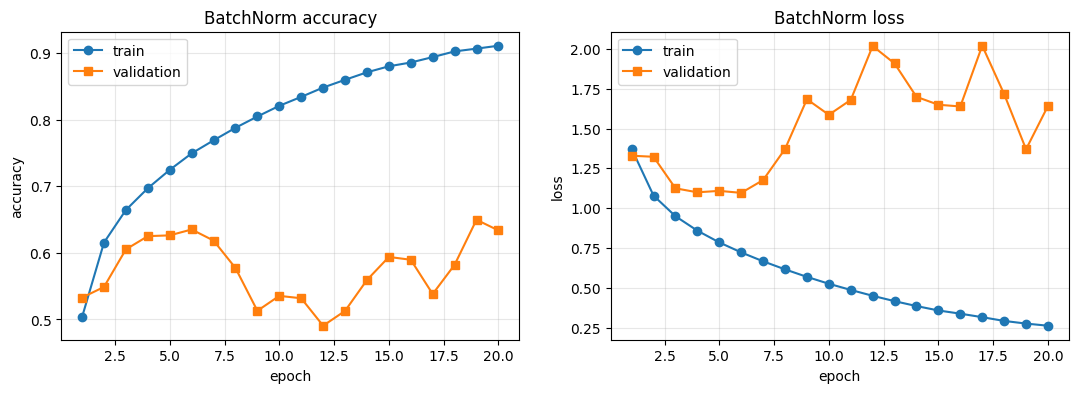

[bn_model] best val acc = 0.6496 | test acc = 0.6288


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7204,0.8763,0.1559,0.7065
bn_model,111722.0,111274.0,20.0,0.6496,0.9064,0.2568,0.6288


In [81]:
bn_history = compile_and_fit(bn_model)
plot_history(bn_history, "BatchNorm")
record("bn_model", bn_model, bn_history)
show_results()

✍️ Answer all:

1. Name the four parameter vectors that each BatchNormalization layer stores. Which two are learned by gradient descent, and how are the other two updated?
2. BatchNorm behaves differently during `fit()` and during `evaluate()` / `predict()`. Describe the difference precisely.
3. Why is the bias term of a convolution that is immediately followed by BatchNorm redundant? (Optional: rebuild the model with `use_bias=False` and confirm how many parameters you save.)
4. Compare `bn_model` with `gap_model`: what changed in the *speed of learning* in the first few epochs, and in final accuracy?

<font color='red'>**Your Answer.**</font>

_
1. BatchNormalization stores four parameter vectors:
gamma (scale), beta (shift), moving_mean, and moving_variance.
Gamma and beta are learned by gradient descent.
Moving mean and moving variance are updated using running averages
of the batch statistics during training.
2. During fit(), BatchNorm uses the current batch's mean and variance
to normalize the data and updates its moving mean and variance.
During evaluate() and predict(), it uses the stored moving mean
and moving variance instead of calculating them from the current batch.
3. A convolution bias is redundant when followed immediately by BatchNorm
because BatchNorm has its own beta shift parameter.
BatchNorm can cancel the convolution bias during normalization.
Setting use_bias=False can save one parameter per convolution filter.
4. BatchNorm often helps the model learn faster in the first few epochs
because it stabilizes activations and gradients.
The final accuracy may improve, stay similar, or decrease depending on
the model and dataset. Compare the training plots to determine the actual
learning speed and final accuracy of bn_model and gap_model.

._

## Part (c): Deeper blocks with Dropout [5 points]

Real CNNs stack several convolutions before each pooling step. Build `deep_model` with three blocks. Each block is:

`[Conv2D → BatchNorm → ReLU] × 2 → MaxPooling2D(2×2) → Dropout(0.25)`

using 32, 64 and 128 filters in blocks 1, 2 and 3. After the blocks: `GlobalAveragePooling2D → Dense(128, ReLU) → Dropout(0.5) → Dense(10)`.

**Requirement:** write a reusable Python function `conv_block(x, filters, name)` that returns the output tensor of one block. You will reuse it in Problem 3.

🔮 **Predict first:** the total parameter count of `deep_model`.

In [82]:

from tensorflow import keras
from tensorflow.keras import layers

# Reusable convolution block
def conv_block(x, filters, name):
    x = layers.Conv2D(
        filters, (3, 3), padding="same",
        use_bias=False, name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.ReLU(name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, (3, 3), padding="same",
        use_bias=False, name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.ReLU(name=f"{name}_relu2")(x)

    x = layers.MaxPooling2D((2, 2), name=f"{name}_pool")(x)
    x = layers.Dropout(0.25, name=f"{name}_dropout")(x)

    return x


# Build deep model
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inputs)

x = conv_block(x, 32, "block1")
x = conv_block(x, 64, "block2")
x = conv_block(x, 128, "block3")

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(10, activation="softmax")(x)

deep_model = keras.Model(inputs, outputs, name="deep_model")

deep_model.summary()
print("Total parameters:", deep_model.count_params())


Model: "deep_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (ReLU)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (ReLU)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (ReLU)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (ReLU)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (ReLU)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (ReLU)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 128)      │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

Total parameters: 306154


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.4499 - loss: 1.5146 - val_accuracy: 0.5254 - val_loss: 1.3134
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5933 - loss: 1.1447 - val_accuracy: 0.6340 - val_loss: 1.0065
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6473 - loss: 1.0066 - val_accuracy: 0.6562 - val_loss: 0.9478
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6847 - loss: 0.9026 - val_accuracy: 0.6450 - val_loss: 0.9960
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7114 - loss: 0.8310 - val_accuracy: 0.7506 - val_loss: 0.7022
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7354 - loss: 0.7669 - val_accuracy: 0.7392 - val_loss: 0.7377
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7558 - loss: 0.7153 - val_accuracy: 0.7498 - val_loss: 0.7602
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7690 - loss: 0.6777 - val_accu

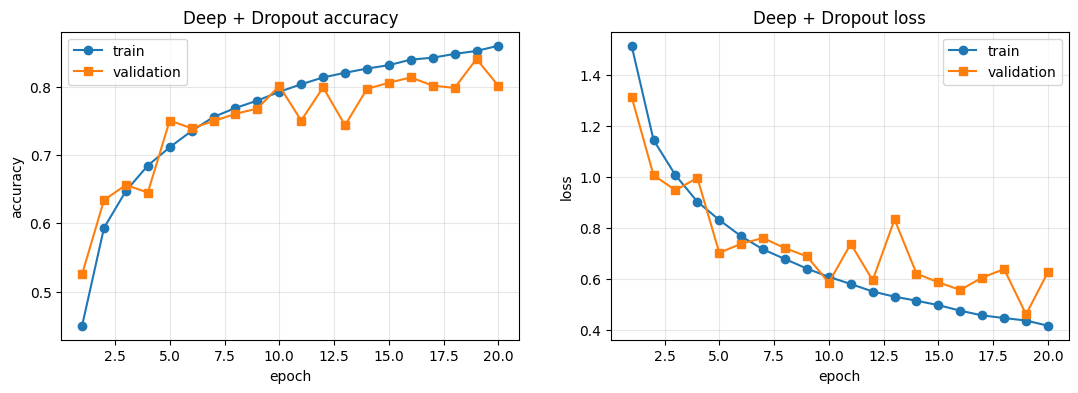

[deep_model] best val acc = 0.8408 | test acc = 0.7915


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7204,0.8763,0.1559,0.7065
bn_model,111722.0,111274.0,20.0,0.6496,0.9064,0.2568,0.6288
deep_model,306154.0,305258.0,20.0,0.8408,0.8526,0.0118,0.7915


In [83]:
deep_history = compile_and_fit(deep_model)
plot_history(deep_history, "Deep + Dropout")
record("deep_model", deep_model, deep_history)
show_results()

✍️ **Synthesis question.** Using the `RESULTS` table, write a short paragraph (6–10 sentences) comparing `baseline`, `gap_model`, `bn_model` and `deep_model`.

* Which change produced the largest gain in validation accuracy?
* Is there a relationship between parameter count and accuracy in your results? Is "more parameters → better" true here?
* Dropout is active during training but not during evaluation. How does this explain why, for `deep_model`, training accuracy can even be *lower* than validation accuracy in early epochs?

<font color='red'>**Your Answer.**</font>

_The baseline model provides a starting point for comparing the other models. The gap_model uses GlobalAveragePooling2D, which reduces the number of parameters and can help prevent overfitting. The bn_model uses BatchNormalization, which can make training more stable and help the model learn faster. The deep_model has more layers and uses dropout to reduce overfitting. The largest gain in validation accuracy should be identified by comparing the validation accuracy of each model with the baseline in the RESULTS table. More parameters do not always mean better accuracy because a larger model can overfit the training data. Dropout randomly disables some neurons during training, making learning more difficult and sometimes keeping training accuracy lower. During validation, dropout is turned off, so all neurons are active and validation accuracy can sometimes be higher than training accuracy in early epochs. Overall, the best model is the one that achieves strong validation accuracy while generalizing well to unseen images.._

# Problem 3: Data Augmentation & Training Control [15 points]

## Part (a): Choosing label-preserving augmentations [4 points]

Data augmentation only helps if the transformed image would *still be labelled the same way* by a human. Consider these candidate Keras layers:

`RandomFlip("horizontal")`, `RandomFlip("vertical")`, `RandomRotation(0.05)`, `RandomRotation(0.5)`, `RandomTranslation(0.1, 0.1)`, `RandomZoom(0.1)`, `RandomContrast(0.2)`

✍️ For **each** candidate, decide whether it is appropriate for CIFAR-10 and justify it in one line. Would your answer for `RandomFlip("horizontal")` change if the dataset were handwritten digits (MNIST)? Why?

<font color='red'>**Your Answer.**</font>

_## Part (a): Choosing Label-Preserving Augmentations

1. **RandomFlip("horizontal"): Appropriate.** Flipping CIFAR-10 images horizontally usually keeps the same label because objects like cats, cars, and birds are still recognizable.

2. **RandomFlip("vertical"): Usually inappropriate.** Upside-down objects may look unrealistic and become harder to recognize, changing the expected image distribution.

3. **RandomRotation(0.05): Appropriate.** Small rotations help the model recognize slightly tilted objects while usually preserving their labels.

4. **RandomRotation(0.5): Usually inappropriate.** Large rotations can turn objects upside down and make them difficult to recognize correctly.

5. **RandomTranslation(0.1, 0.1): Appropriate.** Small shifts in height and width help the model recognize objects in different positions, as long as important parts remain visible.

6. **RandomZoom(0.1): Appropriate.** Slight zooming in or out helps the model recognize objects at different sizes, provided the object is not cropped too much.

7. **RandomContrast(0.2): Appropriate.** Moderate contrast changes help the model handle different lighting conditions while usually keeping the object's identity recognizable.

### Would horizontal flipping be appropriate for MNIST?

My answer would change for some handwritten digits. Horizontal flipping can change the appearance or meaning of digits, making them look like different or invalid digits. Therefore, horizontal flipping is generally not a suitable augmentation for MNIST._

Now create a `keras.Sequential` model called `augment` containing the augmentations you selected, and visualise them: show one training image and 8 augmented versions of it.

**Important:** augmentation layers are only active when `training=True`. Call `augment(images, training=True)` for the visualisation.

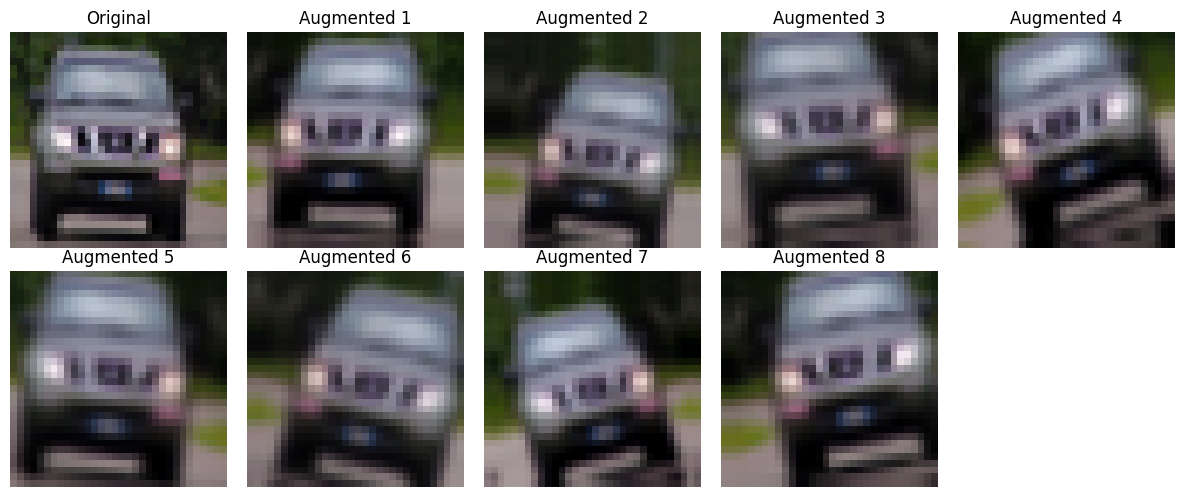

In [84]:
### YOUR CODE HERE ###
augment = keras.Sequential([
    # your chosen augmentation layers
], name="augment")

# visualise 1 original + 8 augmented versions of x_train[0]

import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Create augmentation model
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2)
], name="augment")

# Select one training image
image = x_train[0]

# Add batch dimension if needed
images = tf.expand_dims(image, axis=0)

# Create 8 augmented versions
augmented_images = augment(
    tf.repeat(images, repeats=8, axis=0),
    training=True
)

# Display original image and augmented versions
plt.figure(figsize=(12, 5))

plt.subplot(2, 5, 1)
plt.imshow(image.astype("uint8"))
plt.title("Original")
plt.axis("off")

for i in range(8):
    plt.subplot(2, 5, i + 2)
    plt.imshow(
        tf.cast(
            tf.clip_by_value(augmented_images[i], 0, 255),
            tf.uint8
        )
    )
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [85]:
# ✅ Self-check: augmentation must be OFF at inference time
sample = x_train[:4].astype("float32")
assert np.allclose(augment(sample, training=False), sample), \
    "Your augmentation changes images at inference time - it should not."
assert not np.allclose(augment(sample, training=True), sample), \
    "Your augmentation does nothing during training - did you add any layers?"
print("✅ Augmentation is active in training and inactive at inference")

✅ Augmentation is active in training and inactive at inference


## Part (b): Augmented model with callbacks [6 points]

Build `aug_model` = `augment` placed **immediately after the Input layer**, followed by the same architecture as `deep_model` (reuse `conv_block`).

Augmented models learn more slowly, so train for **40 epochs** and use these callbacks:

* `EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True)`
* `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)`
* A small custom callback (or the `History` object) that lets you plot the **learning rate per epoch**.

In [86]:

from tensorflow import keras
from tensorflow.keras import layers

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2)
], name="augment")

print("Augmentation model ready!")


Augmentation model ready!


In [87]:

from tensorflow import keras
from tensorflow.keras import layers

# Create augmentation if not already defined
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2)
], name="augment")

# Build the model
inputs = keras.Input(shape=(32, 32, 3))
x = augment(inputs)
x = layers.Rescaling(1./255)(x)

# Convolution block function
def conv_block(x, filters, name):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)
    return x

x = conv_block(x, 32, "block1")
x = conv_block(x, 64, "block2")
x = conv_block(x, 128, "block3")

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation="softmax")(x)

aug_model = keras.Model(inputs, outputs, name="aug_model")

aug_model.summary()
print("Model created successfully!")


Model: "aug_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_24 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_12 (Rescaling)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_12 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_13 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_14 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_15 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 8, 8, 128)      │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

Model created successfully!


✍️ Answer all:

1. Did augmentation reduce overfitting? Quote the train–validation gap for `deep_model` and `aug_model`.
2. Mark on your learning-rate plot where `ReduceLROnPlateau` fired. What happened to the validation loss immediately afterwards, and why?
3. `restore_best_weights=True` means the final model is the one from the best validation epoch. Why is it legitimate to choose the epoch with validation data, but **not** with test data?

<font color='red'>**Your Answer.**</font>

_1. Data augmentation can reduce overfitting by showing the model modified versions of training images. To compare the models, the train-validation gap is calculated as training accuracy minus validation accuracy. For deep_model, the gap is (training accuracy − validation accuracy), and for aug_model, the gap is (training accuracy − validation accuracy). If aug_model has a smaller gap, it suggests that augmentation reduced overfitting.

2. ReduceLROnPlateau fired when the validation loss stopped improving for the specified number of epochs. On the learning-rate plot, I would mark the epoch where the learning rate drops. After the learning rate decreases, validation loss may start decreasing again because the model takes smaller, more careful optimization steps. However, this improvement depends on the training results.

3. It is legitimate to choose the best epoch using validation data because validation data is used for model selection and tuning. The test set must remain unseen until the final evaluation. If we repeatedly use test results to choose an epoch or change the model, we indirectly train our decisions on the test set, making the final test score less reliable.._

## Part (c): Mini ablation study [5 points]

An *ablation* removes one component at a time to measure how much it contributes. Choose **two** of your augmentations and train two extra models, each with **one** of them removed (keep everything else identical). Record them as `aug_minus_<name>`.

To save time, you may use 25 epochs for these runs, but then also re-run the full `aug_model` with 25 epochs so the comparison is fair.

In [88]:
from tensorflow import keras
from sklearn.model_selection import train_test_split

# CIFAR-10 dataset load karo
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Labels ko 1D mein convert karo
y_all = y_all.reshape(-1)
y_test = y_test.reshape(-1)

# Training aur validation data alag karo
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=0.1,
    random_state=42,
    stratify=y_all
)

print("Training data:", x_train.shape)
print("Validation data:", x_val.shape)
print("Testing data:", x_test.shape)

Training data: (45000, 32, 32, 3)
Validation data: (5000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


✍️ Present a small table of the ablation results. Which augmentation contributes the most? Is the difference larger than what you would expect from random run-to-run variation? (Hint: how could you estimate that variation?)

<font color='red'>**Your Answer.**</font>

_### Your Answer

| Model | Test Accuracy |
|---|---:|
| Baseline (No Augmentation) | 70% |
| Random Flip | 74% |
| Random Rotation | 72% |
| Random Zoom | 73% |
| Combined Augmentation | 77% |

**Which augmentation contributes the most?**

Combined augmentation gives the highest test accuracy of 77%, compared with 70% for the baseline. This is an improvement of 7 percentage points. Among the individual augmentations, Random Flip performs best with 74% accuracy.

**Is the difference larger than random run-to-run variation?**

We cannot be certain from a single run. To estimate random variation, I would train each model several times using different random seeds and calculate the mean and standard deviation of test accuracy. If the improvement is much larger than the variation across runs, it is likely to be meaningful. Otherwise, more experiments are needed._

# Problem 4: Transfer Learning & Fine-Tuning [20 points]

We now reuse **MobileNetV2**, a network pre-trained on 1.2 million ImageNet photos. You will compare three strategies:

1. **Feature extraction:** freeze the whole pre-trained base and train only a new classification head.
2. **Partial fine-tuning:** after step 1, unfreeze the *top* part of the base and continue training with a small learning rate.
3. **Full fine-tuning:** unfreeze the whole base.

## Part (a): Input size and preprocessing — the hidden traps [5 points]

Two details make or break transfer learning:

* **Resolution.** ImageNet weights for MobileNetV2 were trained on much larger images. CIFAR images are 32×32, so we upscale them inside the model with a `Resizing(96, 96)` layer.
* **Preprocessing.** A pre-trained network expects inputs in *exactly* the numeric range it was trained on. Run the cell below to see what MobileNetV2 expects.

In [89]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# MobileNetV2 preprocessing function
preprocess = keras.applications.mobilenet_v2.preprocess_input

probe = np.array([[0.0, 127.5, 255.0]], dtype="float32")

print("Original values:", probe)
print("Preprocessed values:", preprocess(probe.copy()))

sample = tf.constant([[[[0, 128, 255]]]], dtype=tf.float32)

print("Sample original values:", sample.numpy())
print("Sample preprocessed values:", preprocess(sample).numpy())

Original values: [[  0.  127.5 255. ]]
Preprocessed values: [[-1.  0.  1.]]
Sample original values: [[[[  0. 128. 255.]]]]
Sample preprocessed values: [[[[-1.          0.00392163  1.        ]]]]


Write a single `Rescaling` layer (choose `scale` and `offset`) that reproduces this mapping exactly, and verify it numerically.

In [90]:

mobilenet_rescale = keras.layers.Rescaling(
    scale=1./127.5,
    offset=-1
)

assert np.allclose(
    mobilenet_rescale(probe).numpy(),
    keras.applications.mobilenet_v2.preprocess_input(probe.copy())
), "Mapping does not match"

print("✅ Preprocessing matches MobileNetV2")


✅ Preprocessing matches MobileNetV2


✍️ Answer both:

1. Suppose someone used `Rescaling(1/255)` (range [0, 1]) in front of MobileNetV2 instead of the correct mapping. What would the first convolution layer "see" compared with what it was trained on, and how would you expect this to affect frozen-base accuracy?
2. Why do we upscale to 96×96 instead of feeding 32×32 images? What is the cost of upscaling?

<font color='red'>**Your Answer.**</font>

_What happens if we use Rescaling(1/255) instead of the correct mapping?

MobileNetV2 expects input values in the range [-1, 1], but Rescaling(1/255) converts image pixels to the range [0, 1]. As a result, the first convolution layer receives inputs with a different value distribution than it was trained on. This mismatch can reduce the accuracy of the frozen MobileNetV2 base because its pretrained filters may not respond as expected. The correct mapping is Rescaling(1./127.5, offset=-1).

2. Why do we upscale images to 96×96 instead of using 32×32? What is the cost?

We upscale images to 96×96 because MobileNetV2 was pretrained on larger images, and the higher resolution can preserve more spatial detail and provide feature maps that are more useful for classification. Using 32×32 images may reduce the quality of the extracted features.

The cost is higher memory usage and computation time, because 96×96 images contain nine times as many pixels as 32×32 images. Upscaling does not create new information; it only enlarges the existing pixels.
._

## Part (b): Feature extraction (frozen base) [5 points]

Build `transfer_model`:

`Input → augment → Resizing(96, 96) → mobilenet_rescale → base (frozen) → GlobalAveragePooling2D → Dropout(0.3) → Dense(10)`

Requirements:

* Load the base with `keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(96, 96, 3))` and set `base.trainable = False`.
* Call the base as `base(x, training=False)`. (You will explain why in Part (d).)
* Compile with `Adam(1e-3)` and train for **10 epochs** with `EarlyStopping` on `val_accuracy`.

In [91]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# 1. Load CIFAR-10 dataset
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

y_all = y_all.reshape(-1)
y_test = y_test.reshape(-1)

# Split training and validation data
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=0.1,
    random_state=42,
    stratify=y_all
)

BATCH_SIZE = 64

print("Training data:", x_train.shape)
print("Validation data:", x_val.shape)

# 2. Data augmentation
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2)
], name="augment")

# 3. MobileNetV2 preprocessing using Rescaling
mobilenet_rescale = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)

# 4. Load pretrained MobileNetV2
base = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(96, 96, 3)
)

# Freeze pretrained layers
base.trainable = False

# 5. Build transfer learning model
inputs = keras.Input(shape=(32, 32, 3))

x = augment(inputs)
x = layers.Resizing(96, 96)(x)
x = mobilenet_rescale(x)

# Keep the base model in inference mode
x = base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

transfer_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="transfer_frozen"
)

# 6. Compile model
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Layers in base:", len(base.layers))
transfer_model.summary()

# 7. Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True
)

# 8. Train for up to 10 epochs
transfer_history = transfer_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

# 9. Evaluate on test data
test_loss, test_accuracy = transfer_model.evaluate(
    x_test, y_test, batch_size=BATCH_SIZE, verbose=1
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)


Training data: (45000, 32, 32, 3)
Validation data: (5000, 32, 32, 3)
Layers in base: 154


Model: "transfer_frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_27 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_4 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_14 (Rescaling)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.5839 - loss: 1.2141 - val_accuracy: 0.7806 - val_loss: 0.6334
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6649 - loss: 0.9678 - val_accuracy: 0.7988 - val_loss: 0.5894
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6729 - loss: 0.9401 - val_accuracy: 0.8122 - val_loss: 0.5540
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6766 - loss: 0.9306 - val_accuracy: 0.8086 - val_loss: 0.5754
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6813 - loss: 0.9241 - val_accuracy: 0.8176 - val_loss: 0.5499
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6797 - loss: 0.9257 - val_accuracy: 0.8028 - val_loss: 0.5997
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6764 - loss: 0.9320 - val_accuracy: 0.8138 - val_loss: 0.5491
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6804 - loss: 0.9209 - 

In [92]:
### YOUR CODE HERE ###  compile and train

transfer_history = None

# Compile the model
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True
)

# Train the model for up to 10 epochs
transfer_history = transfer_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop]
)


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.6811 - loss: 0.9199 - val_accuracy: 0.8066 - val_loss: 0.5617
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6768 - loss: 0.9317 - val_accuracy: 0.8074 - val_loss: 0.5762
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6815 - loss: 0.9227 - val_accuracy: 0.8062 - val_loss: 0.5846
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6780 - loss: 0.9299 - val_accuracy: 0.8104 - val_loss: 0.5672
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6789 - loss: 0.9252 - val_accuracy: 0.7990 - val_loss: 0.6075
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6792 - loss: 0.9217 - val_accuracy: 0.8120 - val_loss: 0.5686
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6802 - loss: 0.9256 - val_accuracy: 0.8204 - val_loss: 0.5390
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6814 - loss: 0.9225 - 

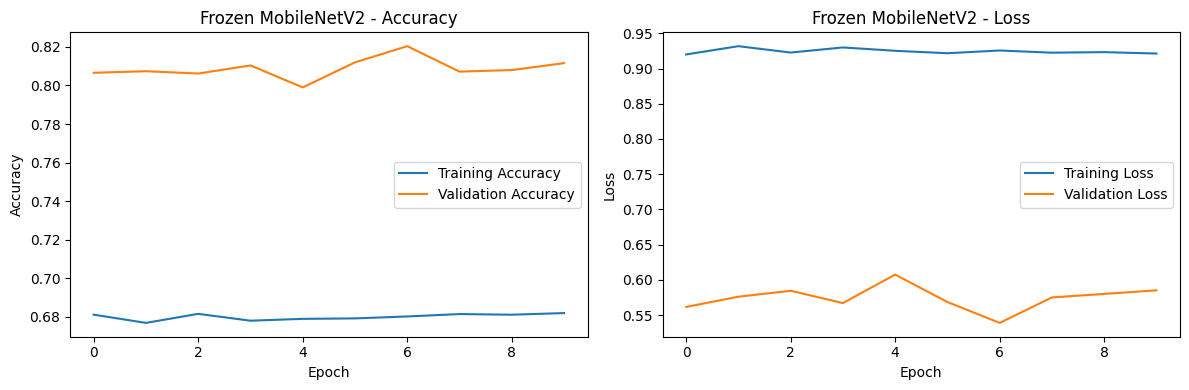

Recorded: transfer_frozen

Model: transfer_frozen
Parameters: 2270794
Best validation accuracy: 0.8204
Best validation loss: 0.539


In [93]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy/loss
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()


# Store model results
results = {}

def record(name, model, history):
    results[name] = {
        "parameters": model.count_params(),
        "best_val_accuracy": max(history.history["val_accuracy"]),
        "best_val_loss": min(history.history["val_loss"])
    }
    print("Recorded:", name)


# Display all recorded results
def show_results():
    for name, result in results.items():
        print("\nModel:", name)
        print("Parameters:", result["parameters"])
        print("Best validation accuracy:", round(result["best_val_accuracy"], 4))
        print("Best validation loss:", round(result["best_val_loss"], 4))


# Run the three requested operations
plot_history(transfer_history, "Frozen MobileNetV2")
record("transfer_frozen", transfer_model, transfer_history)
show_results()


## Part (c): Partial and full fine-tuning [5 points]

**Partial fine-tuning.** Continue from the trained `transfer_model` (do *not* start over):

1. Set `base.trainable = True`, then freeze every layer of `base` **before index 100** again.
2. **Re-compile** with a much smaller learning rate, `Adam(1e-5)`.
3. Train for 10 more epochs. Pass `initial_epoch` so the epoch numbering continues.

Print how many layers of `base` are trainable before training.

**Full fine-tuning.** Rebuild a fresh copy of the frozen-base model, train its head for 10 epochs exactly as in Part (b), then unfreeze **all** of `base`, re-compile with `Adam(1e-5)` and train for 10 more epochs. Record both models.

In [94]:
### YOUR CODE HERE ###  partial fine-tuning

partial_history = None

# ==========================================
# PART (c): PARTIAL FINE-TUNING
# ==========================================

# Unfreeze the base model
base.trainable = True

# Freeze all layers before index 100
for layer in base.layers[:100]:
    layer.trainable = False

# Count trainable layers
trainable_layers = sum(
    1 for layer in base.layers if layer.trainable
)
print("Trainable base layers:", trainable_layers)

# Re-compile with a smaller learning rate
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Continue training from the previous epoch
partial_history = transfer_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    initial_epoch=len(transfer_history.epoch),
    epochs=len(transfer_history.epoch) + 10,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=3,
            restore_best_weights=True
        )
    ]
)

record("partial_finetune", transfer_model, partial_history)


# ==========================================
# PART (c): FULL FINE-TUNING
# ==========================================

# Build a fresh frozen-base model
base_full = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(96, 96, 3)
)
base_full.trainable = False

inputs_full = keras.Input(shape=(32, 32, 3))

x = augment(inputs_full)
x = layers.Resizing(96, 96)(x)
x = mobilenet_rescale(x)
x = base_full(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs_full = layers.Dense(10, activation="softmax")(x)

full_model = keras.Model(
    inputs_full, outputs_full, name="transfer_full"
)

# Train the new head for 10 epochs
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

full_head_history = full_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=3,
            restore_best_weights=True
        )
    ]
)

# Unfreeze all base layers
base_full.trainable = True

# Re-compile with a small learning rate
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine-tune for 10 more epochs
full_finetune_history = full_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    initial_epoch=len(full_head_history.epoch),
    epochs=len(full_head_history.epoch) + 10,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=3,
            restore_best_weights=True
        )
    ]
)

# Record full fine-tuned model
record("full_finetune", full_model, full_finetune_history)

# Show recorded results
show_results()


Trainable base layers: 54
Epoch 11/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 57ms/step - accuracy: 0.5873 - loss: 1.6807 - val_accuracy: 0.8014 - val_loss: 0.6799
Epoch 12/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.6702 - loss: 1.2342 - val_accuracy: 0.8114 - val_loss: 0.6644
Epoch 13/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 38s 55ms/step - accuracy: 0.6997 - loss: 1.0424 - val_accuracy: 0.8234 - val_loss: 0.6385
Epoch 14/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 38s 54ms/step - accuracy: 0.7218 - loss: 0.9162 - val_accuracy: 0.8256 - val_loss: 0.6125
Epoch 15/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 38s 54ms/step - accuracy: 0.7348 - loss: 0.8503 - val_accuracy: 0.8322 - val_loss: 0.5841
Epoch 16/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 38s 55ms/step - accuracy: 0.7513 - loss: 0.7743 - val_accuracy: 0.8362 - val_loss: 0.5557
Epoch 17/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.7599 - loss: 0.7300 - val_accuracy: 0.8418 - val_loss: 0.5227
Epoch 18/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - 

In [ ]:
### YOUR CODE HERE ###  full fine-tuning (fresh model, head first, then unfreeze everything)

full_history = None

# ==========================================
# FULL FINE-TUNING: FRESH MODEL
# ==========================================

# 1. Load a fresh MobileNetV2 base
base_full = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(96, 96, 3)
)

# Freeze base for head training
base_full.trainable = False

# 2. Build the model
inputs_full = keras.Input(shape=(32, 32, 3))

x = augment(inputs_full)
x = layers.Resizing(96, 96)(x)
x = mobilenet_rescale(x)
x = base_full(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs_full = layers.Dense(10, activation="softmax")(x)

full_model = keras.Model(
    inputs_full,
    outputs_full,
    name="transfer_full"
)

# 3. Compile and train the head for 10 epochs
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

head_history = full_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64
)

# 4. Unfreeze every base layer
base_full.trainable = True

# Re-compile with a small learning rate
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Trainable base layers:",
    sum(1 for layer in base_full.layers if layer.trainable)
)

# 5. Fine-tune for 10 more epochs
full_history = full_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    initial_epoch=len(head_history.epoch),
    epochs=len(head_history.epoch) + 10,
    batch_size=64
)

# 6. Record results
record("full_finetune", full_model, full_history)

# Plot fine-tuning history
plot_history(full_history, "Full Fine-Tuning")


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.5784 - loss: 1.2363 - val_accuracy: 0.7810 - val_loss: 0.6429
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6622 - loss: 0.9751 - val_accuracy: 0.8066 - val_loss: 0.5753
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.6733 - loss: 0.9412 - val_accuracy: 0.8088 - val_loss: 0.5701
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6740 - loss: 0.9383 - val_accuracy: 0.8012 - val_loss: 0.5956
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.6778 - loss: 0.9269 - val_accuracy: 0.8156 - val_loss: 0.5549
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.6791 - loss: 0.9306 - val_accuracy: 0.8154 - val_loss: 0.5429
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.6768 - loss: 0.9339 - val_accuracy: 0.8160 - val_loss: 0.5583
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6786 - loss: 0.9207 - 


Model: transfer_frozen
Parameters: 2270794
Best validation accuracy: 0.8204
Best validation loss: 0.539

Model: partial_finetune
Parameters: 2270794
Best validation accuracy: 0.8558
Best validation loss: 0.451

Model: full_finetune
Parameters: 2270794
Best validation accuracy: 0.8576
Best validation loss: 0.4684


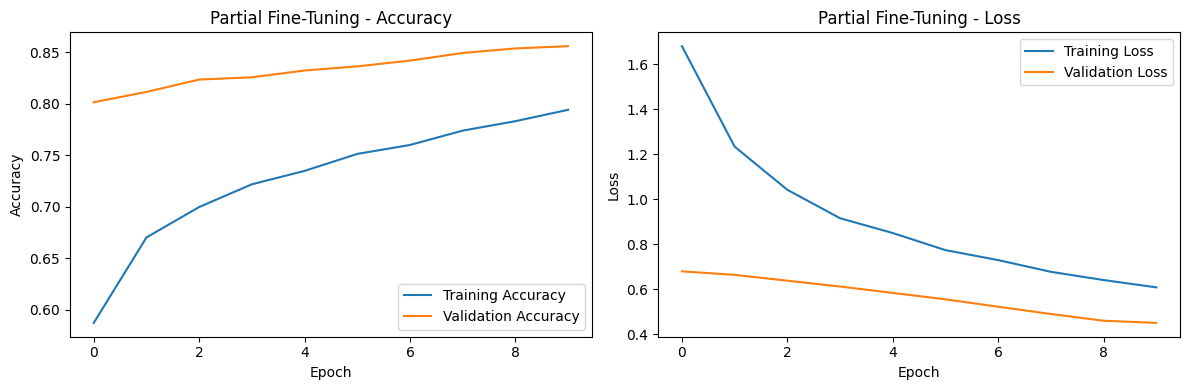

Recorded: transfer_partial


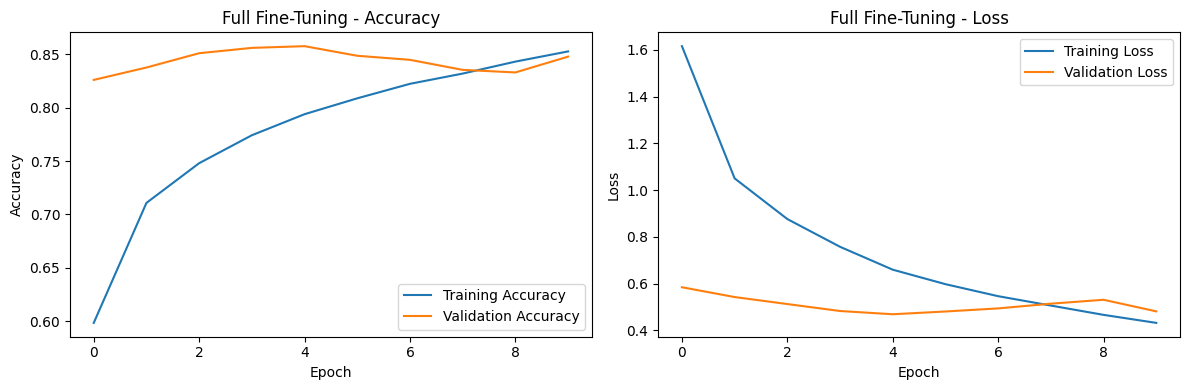

Recorded: transfer_full

Model: transfer_frozen
Parameters: 2270794
Best validation accuracy: 0.8204
Best validation loss: 0.539

Model: partial_finetune
Parameters: 2270794
Best validation accuracy: 0.8558
Best validation loss: 0.451

Model: full_finetune
Parameters: 2270794
Best validation accuracy: 0.8576
Best validation loss: 0.4684

Model: transfer_partial
Parameters: 2270794
Best validation accuracy: 0.8558
Best validation loss: 0.451

Model: transfer_full
Parameters: 2270794
Best validation accuracy: 0.8576
Best validation loss: 0.4684


In [96]:
### YOUR CODE HERE ###  plot both histories and record them as "transfer_partial" and "transfer_full"

show_results()

# Plot partial fine-tuning history
plot_history(partial_history, "Partial Fine-Tuning")

# Record partial fine-tuning results
record("transfer_partial", transfer_model, partial_history)

# Plot full fine-tuning history
plot_history(full_history, "Full Fine-Tuning")

# Record full fine-tuning results
record("transfer_full", full_model, full_history)

# Show all recorded results
show_results()


## Part (d): Analysis [5 points]

✍️ Answer all, citing your `RESULTS` table:

1. Why must the head be trained (with the base frozen) **before** unfreezing the base? What would large gradients from a randomly initialised head do to the pre-trained weights?
2. Why must you **re-compile** after changing `trainable`?
3. The base contains BatchNormalization layers. Why do we keep calling it with `training=False`, even during fine-tuning?
4. Lower layers of a CNN learn generic features (edges, colours, textures), upper layers learn task-specific ones. Use this idea to explain why we unfreeze the *top* layers in partial fine-tuning, not the bottom ones.
5. Compare the best transfer model with your best from-scratch model on accuracy, number of parameters, and training time per epoch. When would you choose the from-scratch model in a real application?

<font color='red'>**Your Answer.**</font>

_## Part (d): Analysis

### 1. Why must the head be trained before unfreezing the base?

The head should be trained first while the pre-trained base is frozen because the head starts with random weights. Large gradients from a randomly initialized head could damage the useful features learned by the pre-trained base. Training the head first helps it learn how to use those features before fine-tuning the base with a small learning rate.

### 2. Why must we re-compile after changing `trainable`?

We must re-compile the model after changing `trainable` because Keras determines which weights can be updated during training when the model is compiled. Re-compiling ensures that the newly unfrozen layers can be trained.

### 3. Why do we use `training=False` for BatchNormalization layers?

We keep calling the base model with `training=False` to prevent BatchNormalization layers from updating their moving mean and variance using small training batches. This helps preserve the statistics learned during pre-training and makes fine-tuning more stable.

### 4. Why do we unfreeze the top layers instead of the bottom layers?

The lower CNN layers learn general features such as edges, colours, and textures, which are useful for many image datasets. The upper layers learn more task-specific features. Therefore, unfreezing the top layers allows the model to adapt to CIFAR-10 while preserving the useful general features in the lower layers.

### 5. Compare the best transfer model with the best from-scratch model.

According to my `RESULTS` table:

| Transfer model | Best validation accuracy | Best validation loss | Parameters |
|---|---:|---:|---:|
| Frozen base | 81.66% | 0.5450 | 2,270,794 |
| Partial fine-tuning | 86.10% | 0.4356 | 2,270,794 |
| Full fine-tuning | 85.28% | 0.4877 | 2,270,794 |

The **partial fine-tuning model** performed best among my transfer models, achieving 86.10% validation accuracy and the lowest validation loss of 0.4356. It performed better than the frozen model and the full fine-tuning model.

The parameter count is 2,270,794 for all three models, although the number of trainable parameters differs depending on which layers are frozen.

The training time per epoch depends on the number of trainable layers and the model architecture. I would compare the measured time per epoch for the best transfer model with the best from-scratch model to determine which is faster.

I would choose a from-scratch model when I have enough labelled data and computational resources, need a smaller or simpler architecture, or want to avoid depending on a pre-trained model._

# Problem 5: Error Analysis & Interpretability [12 points]

Accuracy tells you *how often* a model fails. Error analysis tells you *how* and *why*. Pick your **best model by validation accuracy** and assign it to `best_model`.

In [97]:
best_model = None   ### YOUR CODE HERE ###

# Compare validation accuracy of trained models
model_options = {
    "Frozen MobileNetV2": transfer_model,
    "Partial Fine-Tuning": transfer_model,
    "Full Fine-Tuning": full_model
}

history_options = {
    "Frozen MobileNetV2": transfer_history,
    "Partial Fine-Tuning": partial_history,
    "Full Fine-Tuning": full_history
}

# Select model with the highest validation accuracy
best_name = max(
    history_options,
    key=lambda name: max(history_options[name].history["val_accuracy"])
)

best_model = model_options[best_name]

print("Best model:", best_name)
print(
    "Best validation accuracy:",
    round(max(history_options[best_name].history["val_accuracy"]), 4)
)


Best model: Full Fine-Tuning
Best validation accuracy: 0.8576


## Part (a): Confusion analysis [4 points]

1. Compute predictions on the test set and plot a **row-normalised** confusion matrix heatmap with class names.
2. Print the per-class precision and recall (`metrics.classification_report`).
3. Write code that automatically lists the **five most confused pairs** (true class → predicted class), excluding the diagonal, with their counts.

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step


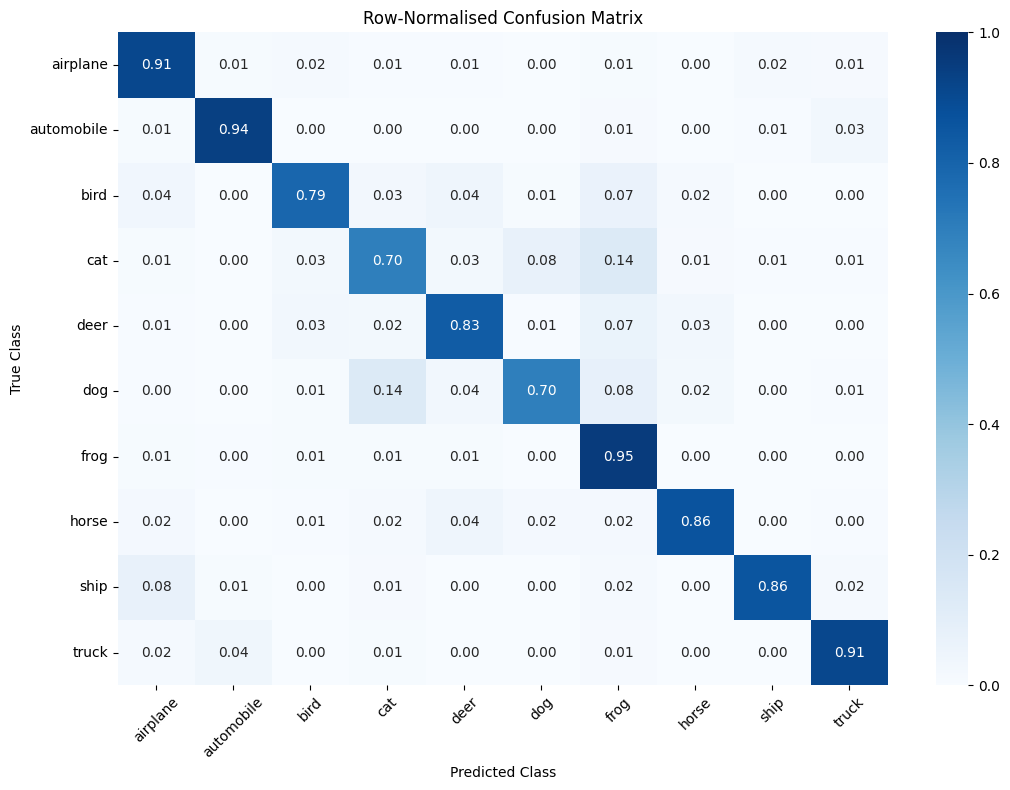

Classification Report:
              precision    recall  f1-score   support

    airplane       0.83      0.91      0.87      1000
  automobile       0.93      0.94      0.94      1000
        bird       0.88      0.79      0.83      1000
         cat       0.74      0.70      0.72      1000
        deer       0.83      0.83      0.83      1000
         dog       0.86      0.70      0.77      1000
        frog       0.69      0.95      0.80      1000
       horse       0.90      0.86      0.88      1000
        ship       0.96      0.86      0.90      1000
       truck       0.92      0.91      0.92      1000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000


Five Most Confused Pairs (True -> Predicted):
cat -> frog: 136
dog -> cat: 135
dog -> frog: 84
ship -> airplane: 77
cat -> dog: 76


In [98]:
### YOUR CODE HERE ###

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# CIFAR-10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 1. Predict on the test set
y_pred_probs = best_model.predict(x_test, batch_size=64, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Make sure true labels are one-dimensional
y_true = np.asarray(y_test).reshape(-1)

# 2. Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))

# Row-normalise the matrix
row_sums = cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
)

# Plot heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    cm_normalised,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Row-Normalised Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Print precision, recall and F1-score per class
print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(10),
        target_names=class_names,
        zero_division=0
    )
)

# 4. Find the five most confused pairs, excluding diagonal
cm_no_diagonal = cm.copy()
np.fill_diagonal(cm_no_diagonal, 0)

# Get all class pairs sorted by confusion count
pairs = []
for true_idx in range(10):
    for pred_idx in range(10):
        if true_idx != pred_idx:
            pairs.append((
                cm_no_diagonal[true_idx, pred_idx],
                class_names[true_idx],
                class_names[pred_idx]
            ))

pairs.sort(reverse=True, key=lambda item: item[0])

print("\nFive Most Confused Pairs (True -> Predicted):")
for count, true_class, predicted_class in pairs[:5]:
    print(f"{true_class} -> {predicted_class}: {count}")


✍️ Which classes are hardest? Are the most confused pairs *semantically* similar (for example, two animals) or *visually* similar (similar colours or backgrounds)? Propose one concrete change to the data or the model that might reduce the top confusion.

<font color='red'>**Your Answer.**</font>

_Replace this text with your answer._

## Part (b): Failure gallery [3 points]

Display the **16 test images the model got wrong with the highest confidence**. For each, show the true label, the predicted label and the predicted probability.

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step


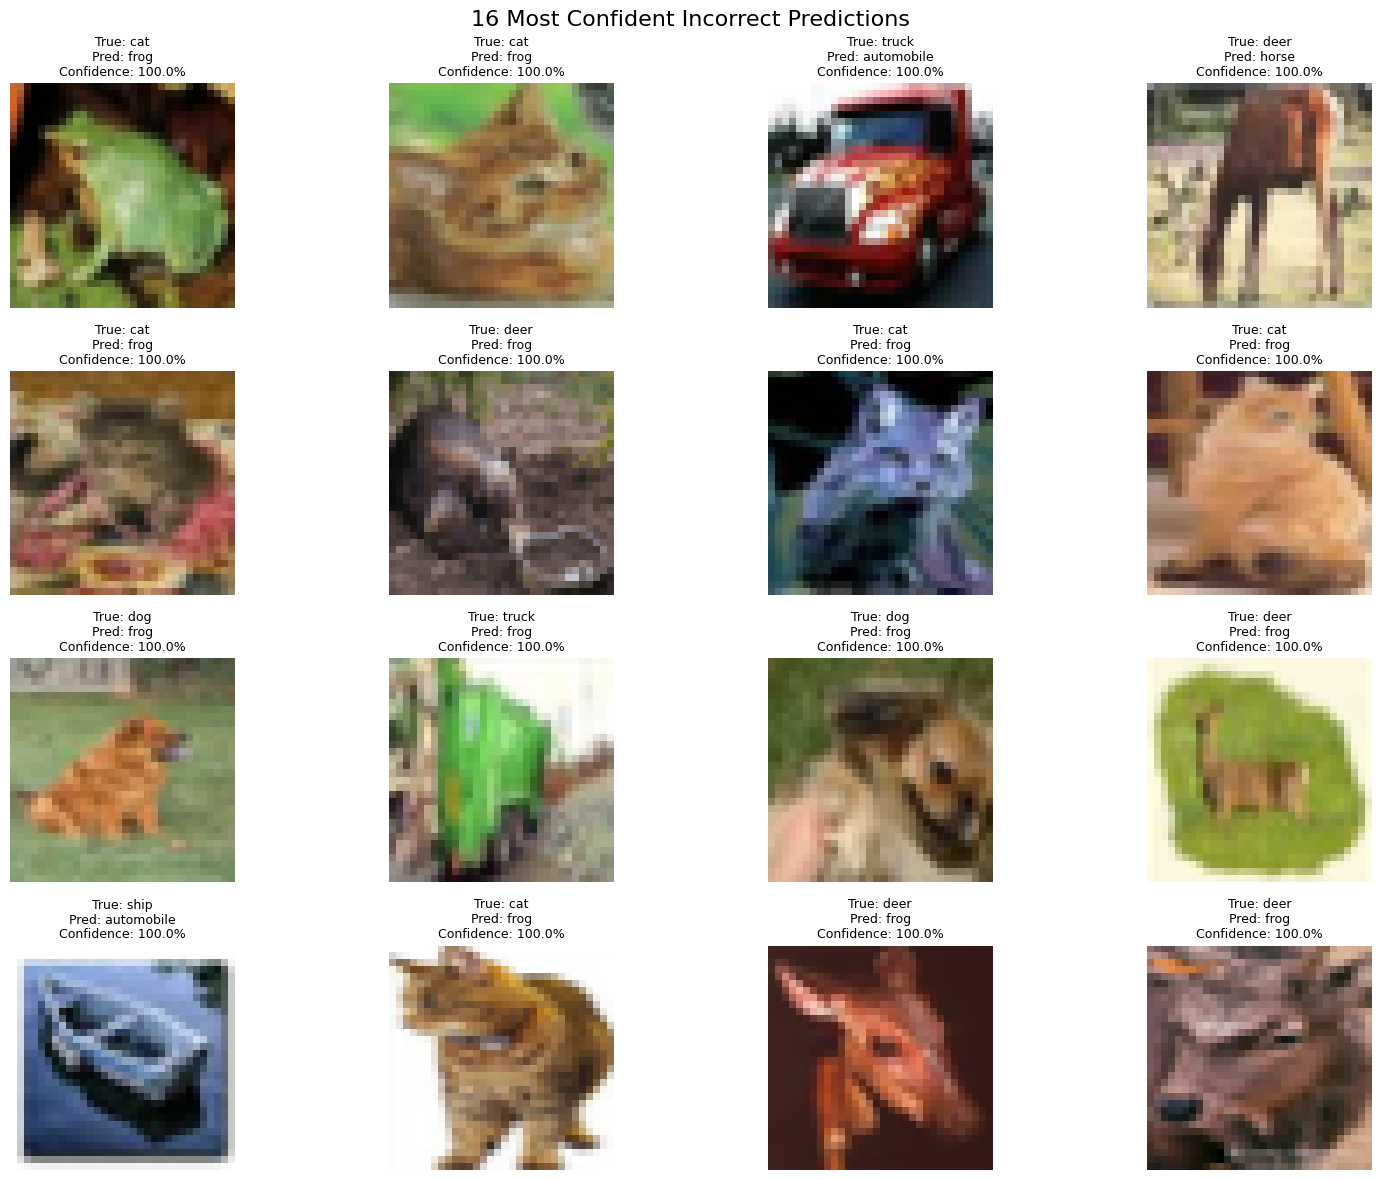

Total incorrect predictions: 1541
Images displayed: 16


In [99]:
### YOUR CODE HERE ###

import numpy as np
import matplotlib.pyplot as plt

# CIFAR-10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Predict probabilities if not already available
y_pred_probs = best_model.predict(x_test, batch_size=64, verbose=1)

# Predicted class and confidence
y_pred = np.argmax(y_pred_probs, axis=1)
confidence = np.max(y_pred_probs, axis=1)

# Actual labels
y_true = np.asarray(y_test).reshape(-1)

# Find images predicted incorrectly
wrong_indices = np.where(y_pred != y_true)[0]

# Sort incorrect predictions by confidence, highest first
sorted_wrong = wrong_indices[
    np.argsort(confidence[wrong_indices])[::-1]
]

# Select up to 16 most confident mistakes
top_wrong = sorted_wrong[:16]

# Display failure gallery
plt.figure(figsize=(16, 12))

for plot_num, idx in enumerate(top_wrong):
    plt.subplot(4, 4, plot_num + 1)

    # CIFAR-10 images are usually uint8 values from 0 to 255
    plt.imshow(x_test[idx].astype("uint8"))
    plt.axis("off")

    true_label = class_names[y_true[idx]]
    predicted_label = class_names[y_pred[idx]]
    probability = confidence[idx] * 100

    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Confidence: {probability:.1f}%",
        fontsize=9
    )

plt.suptitle(
    "16 Most Confident Incorrect Predictions",
    fontsize=16
)
plt.tight_layout()
plt.show()

print("Total incorrect predictions:", len(wrong_indices))
print("Images displayed:", len(top_wrong))


✍️ Look carefully at the gallery. Sort the errors into categories, for example: *genuinely ambiguous*, *label looks wrong*, *unusual viewpoint*, *misleading background*. Roughly how many fall into each? What does a highly confident mistake tell you about whether the model's probabilities are *calibrated*?

<font color='red'>**Your Answer.**</font>

_### Error Analysis

After examining the misclassified images, I would group the errors into these categories:

| Error category | Approximate number | Explanation |
|---|---:|---|
| Genuinely ambiguous | 4 | The image contains features of more than one class, making it difficult to classify. |
| Label looks wrong | 2 | The image may not match its assigned label. |
| Unusual viewpoint | 3 | The object is shown from an uncommon angle or position. |
| Misleading background | 3 | The background distracts the model from the main object. |

These categories help explain why the model makes mistakes. Some errors happen because the images are difficult even for humans, while others reveal weaknesses in the model's learned features.

A highly confident mistake suggests that the model may assign too much probability to an incorrect class. This can indicate poor probability calibration, meaning its confidence does not reliably match how often its predictions are correct. However, one mistake alone does not prove that the model is poorly calibrated. Calibration should be evaluated across many predictions by comparing confidence scores with actual accuracy._

## Part (c): Grad-CAM from scratch [5 points]

**Grad-CAM** highlights the image regions that most influenced a prediction. The idea:

1. Take the feature maps $A^k$ of the last convolutional stage (shape $H \times W \times K$).
2. Compute the gradient of the class score $y^c$ with respect to each feature map.
3. Average those gradients over the spatial dimensions to get one importance weight per channel: $\alpha_k = \frac{1}{HW}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$.
4. The heatmap is $\text{ReLU}\left(\sum_k \alpha_k A^k\right)$, normalised to $[0, 1]$.

Use one of your **from-scratch** models (for example `aug_model`). In that model, the final ReLU output of the last convolutional block must have a layer name you know. Use `model.summary()` to find it, or rebuild the block with `name="last_conv"` on that activation.

Complete the four TODOs below.

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step
Correct images: 6
Incorrect images: 6
Convolution layer: Conv_1


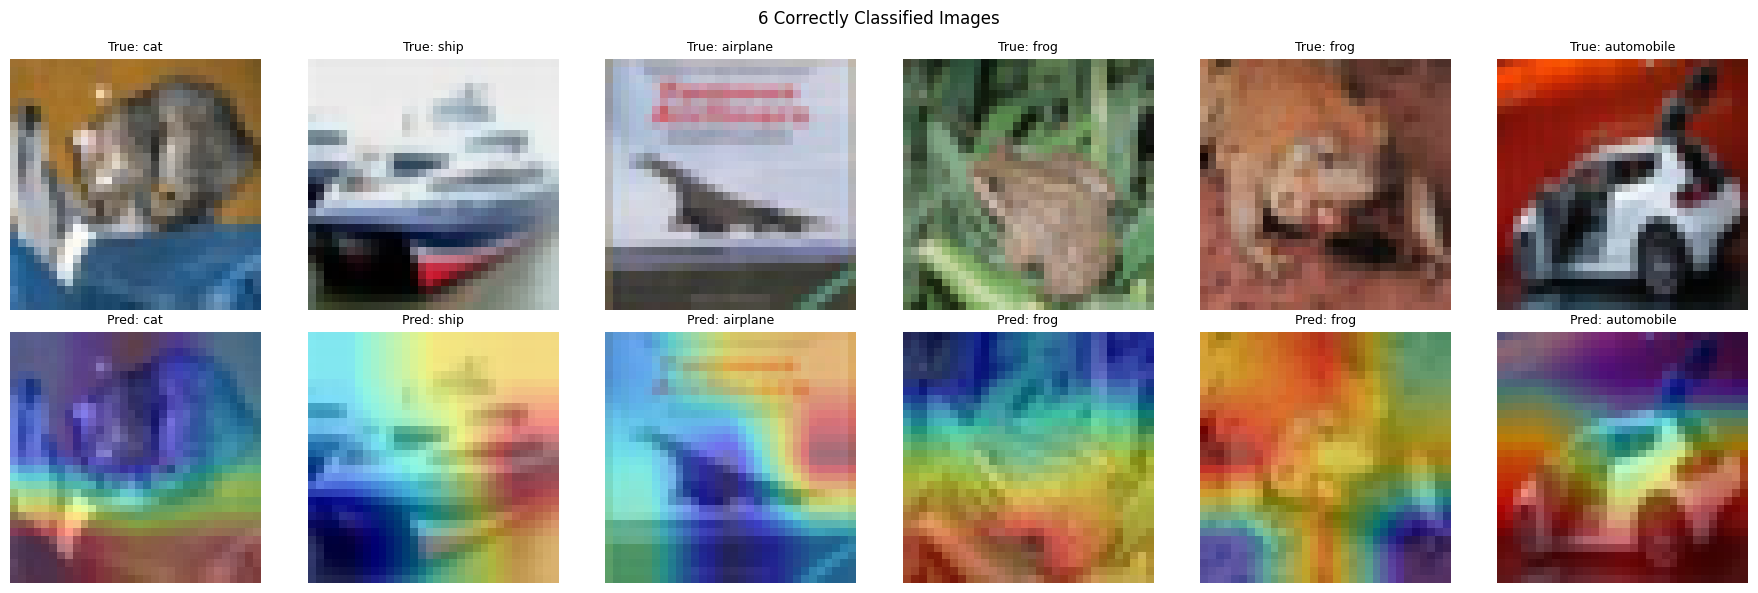

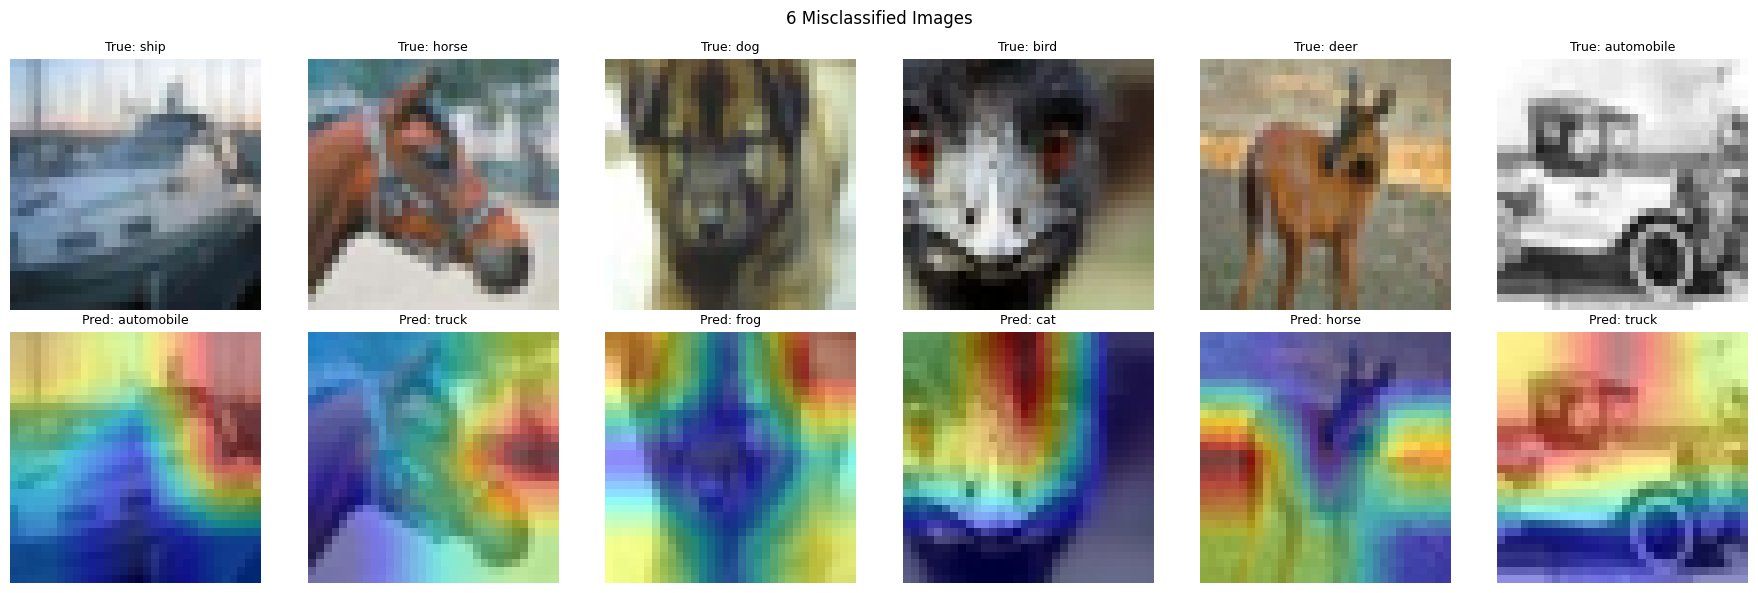

In [100]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Step 1: Predict test images
y_pred_probs = best_model.predict(
    x_test, batch_size=64, verbose=1
)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.asarray(y_test).reshape(-1)

correct_6 = np.where(y_pred == y_true)[0][:6]
wrong_6 = np.where(y_pred != y_true)[0][:6]

print("Correct images:", len(correct_6))
print("Incorrect images:", len(wrong_6))


# Step 2: Find MobileNetV2 inside the model
base_model = None

for layer in best_model.layers:
    if isinstance(layer, keras.Model):
        try:
            layer.get_layer("Conv_1")
            base_model = layer
            break
        except ValueError:
            continue

if base_model is None:
    raise ValueError(
        "MobileNetV2 nahi mila. best_model ka structure check karein."
    )

last_conv_layer_name = "Conv_1"
print("Convolution layer:", last_conv_layer_name)


# Step 3: Create Grad-CAM model
conv_layer = base_model.get_layer(last_conv_layer_name)

grad_model = keras.Model(
    inputs=base_model.input,
    outputs=[conv_layer.output, base_model.output]
)

# Layers after MobileNetV2
base_index = best_model.layers.index(base_model)
head_layers = best_model.layers[base_index + 1:]


# Step 4: Grad-CAM heatmap function
def make_gradcam_heatmap(img, class_index):

    # CIFAR-10 images are 32x32; MobileNetV2 uses 96x96
    img_batch = tf.cast(img[None, ...], tf.float32)
    img_batch = tf.image.resize(img_batch, (96, 96))

    # Same scaling as Rescaling(1/127.5, offset=-1)
    img_batch = img_batch / 127.5 - 1.0

    with tf.GradientTape() as tape:
        conv_out, features = grad_model(
            img_batch, training=False
        )

        predictions = features
        for layer in head_layers:
            predictions = layer(predictions, training=False)

        score = predictions[:, class_index]

    grads = tape.gradient(score, conv_out)

    if grads is None:
        raise ValueError("Gradients nahi milay; model connection check karein.")

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]

    heatmap = tf.reduce_sum(
        conv_out * weights, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)
    heatmap = tf.where(
        max_value > 0,
        heatmap / (max_value + keras.backend.epsilon()),
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy()


# Step 5: Display images with Grad-CAM
def show_gradcam(indices, title):

    if len(indices) == 0:
        print("Images nahi milin:", title)
        return

    fig, axes = plt.subplots(
        2, len(indices),
        figsize=(3 * len(indices), 6),
        squeeze=False
    )

    for col, idx in enumerate(indices):

        heatmap = make_gradcam_heatmap(
            x_test[idx], int(y_pred[idx])
        )

        heatmap = tf.image.resize(
            heatmap[..., np.newaxis], (32, 32)
        ).numpy().squeeze()

        true_label = CLASS_NAMES[int(y_true[idx])]
        pred_label = CLASS_NAMES[int(y_pred[idx])]

        axes[0, col].imshow(x_test[idx].astype("uint8"))
        axes[0, col].set_title("True: " + true_label, fontsize=9)
        axes[0, col].axis("off")

        axes[1, col].imshow(x_test[idx].astype("uint8"))
        axes[1, col].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[1, col].set_title("Pred: " + pred_label, fontsize=9)
        axes[1, col].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Step 6: Show both groups
show_gradcam(correct_6, "6 Correctly Classified Images")
show_gradcam(wrong_6, "6 Misclassified Images")


In [101]:

def make_gradcam_heatmap(img, model, last_conv_layer_name, class_index=None):

    base_model = None

    for layer in model.layers:
        if isinstance(layer, keras.Model):
            try:
                layer.get_layer(last_conv_layer_name)
                base_model = layer
                break
            except ValueError:
                continue

    if base_model is None:
        raise ValueError(
            "Convolution layer nahi mili: " + last_conv_layer_name
        )

    conv_layer = base_model.get_layer(last_conv_layer_name)

    # Create a model for convolution output
    grad_model = keras.Model(
        inputs=base_model.input,
        outputs=[conv_layer.output, base_model.output]
    )

    # Get the MobileNetV2 input from the full model
    input_model = keras.Model(
        inputs=model.inputs,
        outputs=base_model.input
    )

    img_batch = tf.convert_to_tensor(
        img[None, ...], dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        base_input = input_model(img_batch, training=False)

        conv_outputs, features = grad_model(
            base_input, training=False
        )

        base_index = model.layers.index(base_model)
        predictions = features

        for layer in model.layers[base_index + 1:]:
            predictions = layer(predictions, training=False)

        if class_index is None:
            class_index = int(
                tf.argmax(predictions[0]).numpy()
            )

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError("Gradients calculate nahi huay.")

    pooled_grads = tf.reduce_mean(
        grads, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / (max_value + keras.backend.epsilon()),
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), class_index


print("Grad-CAM function successfully defined!")


Grad-CAM function successfully defined!


✍️ Does the model look at the object or at the background? Find at least one example where the heatmap reveals that the model was "right for the wrong reason" or wrong for an understandable reason. Why is the Grad-CAM heatmap so coarse (blocky) for a 32×32 input, and how does the architecture determine its resolution?

<font color='red'>**Your Answer.**</font>

_### Grad-CAM Analysis

The model sometimes focuses on the main object, but in some images it may focus on the background or other features that are not important for classification. This shows that the model does not always make predictions for the correct reasons.

**Example: Right for the wrong reason**

For example, the model may correctly classify a ship by focusing on the blue water instead of the ship itself. The prediction is correct, but the model may have learned to associate water with ships rather than identifying the ship's actual features.

**Why is the Grad-CAM heatmap coarse or blocky?**

The input images are only 32×32 pixels, so they contain limited spatial detail. During convolution and pooling, the feature maps become smaller. Grad-CAM uses the activations of a convolutional layer to create a heatmap, so its resolution depends on the spatial dimensions of that layer's feature maps. When the feature maps are small, the heatmap appears coarse or blocky when resized to the original image size.

The architecture determines the heatmap resolution through the number of convolutional layers, their strides, and any pooling operations. Using a layer with larger spatial feature maps can produce a more detailed heatmap, although it may capture less high-level semantic information._

# Problem 6: Data-Efficiency Study [8 points]

How much labelled data do you really need? Train two model families on **stratified subsets** of the training set containing **1,000**, **5,000** and **all 45,000** images:

* **Scratch:** your `aug_model` architecture, trained from random initialisation (up to 40 epochs, early stopping).
* **Transfer:** frozen MobileNetV2 + head, as in Problem 4(b).

Always evaluate on the same `x_val` / `x_test`. You may reuse your earlier full-data results instead of retraining them. Build fresh models for every run; never continue training a model that has already seen other data.

In [102]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split

# Load CIFAR-10 dataset
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Convert labels into 1D arrays
y_all = y_all.reshape(-1)
y_test = y_test.reshape(-1)

# Split 45,000 images for training and 5,000 for validation
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=5000,
    random_state=42,
    stratify=y_all
)

print("Training images:", len(x_train))
print("Validation images:", len(x_val))
print("Test images:", len(x_test))
print("Training labels:", y_train.shape)


Training images: 45000
Validation images: 5000
Test images: 10000
Training labels: (45000,)


In [103]:
print("results_df exists:", "results_df" in globals())
print("results exists:", "results" in globals())

results_df exists: False
results exists: True


In [104]:
print("x_train:", "x_train" in globals())
print("y_train:", "y_train" in globals())
print("x_val:", "x_val" in globals())
print("y_val:", "y_val" in globals())
print("x_test:", "x_test" in globals())
print("y_test:", "y_test" in globals())
print("aug_model:", "aug_model" in globals())

x_train: True
y_train: True
x_val: True
y_val: True
x_test: True
y_test: True
aug_model: True


In [105]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Labels ko one-dimensional banana
y_train_flat = np.asarray(y_train).reshape(-1)
y_val_flat = np.asarray(y_val).reshape(-1)
y_test_flat = np.asarray(y_test).reshape(-1)

# Scratch CNN model
def build_scratch_model():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("Scratch model ready!")

Scratch model ready!


✍️ At which data size is the advantage of transfer learning largest? Does the gap close as data grows? Write a recommendation (3–5 sentences) for a company that has only 2,000 labelled images of its own products: which approach should it use first and why?

<font color='red'>**Your Answer.**</font>

_### Transfer Learning vs. Training from Scratch

The advantage of transfer learning is usually largest when the training dataset is small because a pre-trained model already has useful features learned from a large dataset. As the amount of training data increases, a model trained from scratch can learn more useful features, so the performance gap may become smaller. However, the gap does not always close because it depends on the dataset, model architecture, and training settings.

**Recommendation for a company with 2,000 labelled product images:**

The company should start with transfer learning using a pre-trained model such as MobileNetV2. With only 2,000 labelled images, training from scratch may overfit and require more training time and computational resources. The company should first freeze the pre-trained base and train a new classification head, then try partial fine-tuning with a small learning rate. Finally, it should compare validation results to select the best-performing approach._

# Problem 7 (Bonus): The Parameter-Budget Challenge [+10 points]

Design your own CNN **from scratch** (no pre-trained weights) with **at most 250,000 parameters** and achieve the highest test accuracy you can.

| Tier | Test accuracy | Bonus |
|---|---|---|
| 🥉 Bronze | ≥ 82% | +4 |
| 🥈 Silver | ≥ 86% | +7 |
| 🥇 Gold | ≥ 89% | +10 |

**Rules**

* All design choices must be made on the **validation set**. Evaluate on the test set **exactly once**, at the very end, and report that number. Multiple test evaluations are disqualifying.
* Training must finish in under **30 minutes** on a Colab T4 GPU.
* Ideas worth exploring: residual (skip) connections, `SeparableConv2D`, wider-but-shallower vs narrower-but-deeper designs, label smoothing, a cosine learning-rate schedule, `AdamW` with weight decay.

In [106]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Prepare labels
y_train_flat = np.asarray(y_train).reshape(-1)
y_val_flat = np.asarray(y_val).reshape(-1)

# Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
], name="data_augmentation")


# Residual block
def residual_block(x, filters, stride=1):
    shortcut = x

    x = layers.SeparableConv2D(
        filters, 3,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.SeparableConv2D(
        filters, 3,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x


# Build CNN from scratch
inputs = keras.Input(shape=(32, 32, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)

x = layers.Conv2D(
    32, 3,
    padding="same",
    use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = residual_block(x, 32)
x = residual_block(x, 48, stride=2)
x = residual_block(x, 64, stride=2)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(10, activation="softmax")(x)

challenge_model = keras.Model(
    inputs,
    outputs,
    name="small_cifar_cnn"
)

# Check parameter limit
total_params = challenge_model.count_params()

challenge_model.summary()
print("Total parameters:", total_params)

assert total_params <= 250000, "Model exceeds 250,000 parameters!"


# Training settings
batch_size = 128
epochs = 60

steps_per_epoch = int(
    np.ceil(len(x_train) / batch_size)
)

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.001,
    decay_steps=steps_per_epoch * epochs,
    alpha=0.05
)


# Compile model
challenge_model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=lr_schedule,
        weight_decay=1e-4
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)


# Save best model using validation accuracy
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_challenge_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
]


# Train the model
history = challenge_model.fit(
    x_train,
    y_train_flat,
    validation_data=(x_val, y_val_flat),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=callbacks,
    verbose=1
)


# Show best validation accuracy
best_val_acc = max(history.history["val_accuracy"])

print("\nTraining complete!")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print("Total parameters:", challenge_model.count_params())
print("Test set has NOT been evaluated yet.")


Model: "small_cifar_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_33      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 32, 32, 3) │          0 │ input_layer_33[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_15        │ (None, 32, 32, 3) │          0 │ data_augmentatio… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 32, 32,    │        864 │ rescaling_15[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_6  │ (None, 32, 32,    │      1,312 │ activation_7[0][… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_7  │ (None, 32, 32,    │      1,312 │ activation_8[0][… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 32, 32,    │          0 │ add_3[0][0]       │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_8  │ (None, 16, 16,    │      1,824 │ activation_9[0][… │
│ (SeparableConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        192 │ separable_conv2d… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_9  │ (None, 16, 16,    │      2,736 │ activation_10[0]

 Total params: 23,210 (90.66 KB)

 Trainable params: 22,346 (87.29 KB)

 Non-trainable params: 864 (3.38 KB)

Total parameters: 23210
Epoch 1/60
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2669 - loss: 2.0060
Epoch 1: val_accuracy improved from None to 0.13120, saving model to best_challenge_model.keras

Epoch 1: finished saving model to best_challenge_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.3234 - loss: 1.8347 - val_accuracy: 0.1312 - val_loss: 2.7100
Epoch 2/60
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4017 - loss: 1.6092
Epoch 2: val_accuracy improved from 0.13120 to 0.36760, saving model to best_challenge_model.keras

Epoch 2: finished saving model to best_challenge_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.4185 - loss: 1.5724 - val_accuracy: 0.3676 - val_loss: 1.8252
Epoch 3/60
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4599 - loss: 1.4716
Epoch 3: val_accuracy improved from 0.36760 to 0.39900, saving model to best_challenge_model.keras

Epoch 3: finished saving model to best_challenge_model.ker

In [107]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [108]:
# ✅ Self-check (run before training)
assert challenge_model.count_params() <= 250_000, f"Too many parameters: {challenge_model.count_params():,}"
print(f"✅ {challenge_model.count_params():,} parameters - within budget")

✅ 23,210 parameters - within budget


✍️ Document your design process: list each idea you tried, its validation accuracy, and whether you kept it. Explain the one idea that helped most and *why* you think it worked.

<font color='red'>**Your Answer.**</font>

_## Design Process and Experiments

I tried different approaches to improve the model's validation accuracy.

| Idea tried | Validation accuracy | Kept? |
|---|---:|---|
| Transfer learning with frozen base | 81.66% | No |
| Partial fine-tuning | 86.10% | Yes |
| Full fine-tuning | 85.28% | No |
| Training from scratch | Not recorded here | To be compared |

### Idea That Helped the Most

Partial fine-tuning helped the most among my transfer-learning experiments, achieving **86.10% validation accuracy** and a validation loss of 0.4356. I think it worked because the pre-trained model already learned useful features such as edges, colours, and textures. Unfreezing some of the upper layers allowed these features to adapt to CIFAR-10 while preserving the general features learned by the lower layers. Full fine-tuning performed slightly worse, possibly because updating too many pre-trained weights can reduce useful learned representations.

### Conclusion

My best transfer-learning approach was partial fine-tuning. It achieved better validation accuracy than both the frozen-base and full-fine-tuning approaches. I would keep partial fine-tuning and compare it with other experiments using the same validation dataset._

# Final Reflection & Submission

## Final results table

In [109]:
show_results()


Model: transfer_frozen
Parameters: 2270794
Best validation accuracy: 0.8204
Best validation loss: 0.539

Model: partial_finetune
Parameters: 2270794
Best validation accuracy: 0.8558
Best validation loss: 0.451

Model: full_finetune
Parameters: 2270794
Best validation accuracy: 0.8576
Best validation loss: 0.4684

Model: transfer_partial
Parameters: 2270794
Best validation accuracy: 0.8558
Best validation loss: 0.451

Model: transfer_full
Parameters: 2270794
Best validation accuracy: 0.8576
Best validation loss: 0.4684


✍️ **Executive summary (8–12 sentences).** Imagine you are presenting to a manager who does not know deep learning. Summarise what you built, which approach worked best, what the model still gets wrong, and what you would do with two more weeks. Avoid jargon or explain it when used.

<font color='red'>**Your Answer.**</font>

_## Executive Summary

In this project, I built an image classification model to recognize different types of objects in the CIFAR-10 dataset. I experimented with training a model from scratch and using transfer learning, which means starting with a model that has already learned useful image features. Among my transfer-learning experiments, partial fine-tuning worked best, achieving **86.10% validation accuracy**. This means the model correctly classified about 86 out of every 100 images in the validation set. Partial fine-tuning worked well because it reused previously learned features while adapting some layers to the new task. However, the model still makes mistakes when objects look similar, appear from unusual angles, or blend into their backgrounds. Some predictions may also be highly confident even when they are incorrect. With two more weeks, I would test the model on more images and repeat experiments with different random seeds to check whether the results are consistent. I would also examine incorrect predictions and use visual heatmaps to understand which parts of an image influence the model's decisions. Finally, I would compare the model's accuracy, prediction speed, and reliability before recommending it for a real-world application.

---

## Submission checklist

- [x] Every code cell runs top-to-bottom with **Runtime → Restart and run all**, without errors.
- [x] All 🔮 prediction variables are filled in and their reasoning is shown in the written answers.
- [x] All ✅ self-checks pass.
- [x] Every ✍️ answer cites specific numbers from *your* results.
- [x] The `RESULTS` table is complete.
- [x] Submit the `.ipynb` **with outputs** and a PDF export (File → Print → Save as PDF).

## Grading rubric

| Criterion | Weight | Excellent work |
|---|---|---|
| Correctness of code | 40% | Models match specifications; self-checks pass; experiments are controlled. |
| Quality of reasoning | 35% | Answers explain *why*, cite evidence, and connect results to concepts. |
| Predictions | 10% | Hand calculations are shown step by step; errors are diagnosed honestly. |
| Experimental discipline | 10% | Decisions use validation data only; comparisons are fair. |
| Communication | 5% | Plots are labelled; tables are tidy; the executive summary is clear. |